# Stage 1 — Azure Dataset Preparation and Temporal Windowing

**Objective:** turn the Microsoft Azure Predictive Maintenance telemetry into clean, normalized, chronologically ordered sensor windows that the Stage 2 encoder and temporal predictor can consume directly.

The dataset holds hourly telemetry from 100 **simulated** machines during 2015, plus failure, maintenance, error and machine records. It is a simulated benchmark, not measurements from a physical factory.

Only the four telemetry variables (voltage, rotation, pressure, vibration) become model inputs. Failure and maintenance records are kept **separately**, for evaluation and interpretation in later stages.

No neural network is trained in this stage.

| Step | Task |
|---|---|
| 1.1 | Load and inspect the Azure dataset |
| 1.2 | Explore sensor behavior and failure events |
| 1.3 | Clean and organize the telemetry |
| 1.4 | Split the dataset chronologically |
| 1.5 | Normalize the four sensors |
| 1.6 | Create 6-hour sensor blocks |
| 1.7 | Construct historical context and future targets |
| 1.8 | Prepare masks, metadata and PyTorch DataLoaders |
| 1.9 | Validate and save the processed dataset |

### Setup

In [1]:
# =============================================================================
# Imports
# =============================================================================
from pathlib import Path  # Object-oriented file paths; "/" joins path parts on any OS.
import pickle             # Saves the fitted StandardScaler object to scaler.pkl.

import matplotlib.pyplot as plt  # Every figure in this notebook.
import numpy as np               # Arrays: blocking and windowing are done with NumPy reshapes and indexing.
import pandas as pd              # Loading the CSV files, timestamps, grouping by machine.
import torch                     # Tensors and the Dataset/DataLoader classes used in Step 1.8.
import yaml                      # Reads configs/base.yaml (the Stage 0 configuration).
from sklearn.preprocessing import StandardScaler  # Per-sensor (x - mean) / std, fitted on training rows only.
from torch.utils.data import DataLoader, Dataset

# =============================================================================
# Locate the project root
# =============================================================================
# The notebook may be run from notebooks/, working/..., or the project root.
# Walk upwards from the current directory until we find the folder holding pyproject.toml.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root (no pyproject.toml found).")

# =============================================================================
# Shared configuration from Stage 0
# =============================================================================
with (PROJECT_ROOT / "configs" / "base.yaml").open(encoding="utf-8") as f:
    config = yaml.safe_load(f)

data_cfg = config["data"]
SENSORS = data_cfg["sensor_names"]           # ['voltage', 'rotation', 'pressure', 'vibration'], the column order everywhere
NUM_SENSORS = data_cfg["num_sensors"]        # 4
BLOCK_SIZE = data_cfg["block_size"]          # 6 hourly observations per block
CONTEXT_LENGTH = data_cfg["context_length"]  # 4 historical blocks per sample
BATCH_SIZE = config["training"]["batch_size"]["azure"]  # 128
SEED = config["training"]["random_seeds"][0]            # 11, used for the training-loader shuffle

HOUR = pd.Timedelta(hours=1)
BLOCK = pd.Timedelta(hours=BLOCK_SIZE)  # 6 hours
BLOCK_FREQ = f"{BLOCK_SIZE}h"           # "6h": pandas frequency string; floor("6h") snaps a time to 00:00/06:00/12:00/18:00

# The Azure CSV calls the sensors volt/rotate/pressure/vibration. We rename them to the
# config names once, in Step 1.3, so every later array uses the same column order as the config.
AZURE_TO_CONFIG = {"volt": "voltage", "rotate": "rotation", "pressure": "pressure", "vibration": "vibration"}
AZURE_SENSORS = list(AZURE_TO_CONFIG)  # ['volt', 'rotate', 'pressure', 'vibration']
assert list(AZURE_TO_CONFIG.values()) == SENSORS, "sensor order in the config must match the Azure columns"

# Chronological split proportions (Step 1.4).
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
PARTITIONS = list(SPLIT_FRACTIONS)  # ['train', 'val', 'test'], also their time order

# =============================================================================
# Folders
# =============================================================================
def find_csv(folder, name):
    """Return the CSV in `folder` whose file name equals `name` ignoring case, or None.

    Kaggle downloads differ in capitalization (PdM_telemetry.csv vs pdm_telemetry.csv).
    """
    matches = [p for p in folder.glob("*.csv") if p.name.lower() == name.lower()]
    return matches[0] if matches else None


# The raw Azure CSVs: the instructions put them in data/raw/. We look there first and then
# in the folder the Kaggle archive was unpacked into, and use the first folder that has the telemetry.
RAW_CANDIDATES = [
    PROJECT_ROOT / "data" / "raw",
    PROJECT_ROOT / "data" / "raw" / "azure",
    PROJECT_ROOT / "data" / "Microsoft_Azure_Predictive_Maintenance",
]
AZURE_DIR = next((d for d in RAW_CANDIDATES if d.is_dir() and find_csv(d, "PdM_telemetry.csv")), None)
if AZURE_DIR is None:
    raise FileNotFoundError(f"PdM_telemetry.csv not found in any of {[str(d) for d in RAW_CANDIDATES]}")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"  # model-ready tensors, metadata and scaler
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
for path in (PROCESSED_DIR, FIGURES_DIR, RESULTS_DIR):
    path.mkdir(parents=True, exist_ok=True)

# =============================================================================
# Plot styling
# =============================================================================
# One fixed colour per sensor (same as the synthetic notebook) and one per failed component.
# The two sets never share a colour, so a colour always means the same thing in every figure.
SENSOR_COLORS = dict(zip(SENSORS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
COMPONENTS = ["comp1", "comp2", "comp3", "comp4"]
COMPONENT_COLORS = dict(zip(COMPONENTS, ["#e87ba4", "#008300", "#6250d6", "#e34948"]))
PARTITION_STYLES = {"train": "-", "val": "--", "test": ":"}  # line style per partition in histograms
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "grid.linewidth": 0.5})

print(f"Project root:  {PROJECT_ROOT}")
print(f"Azure CSVs:    {AZURE_DIR.relative_to(PROJECT_ROOT)}")
print(f"Block size: {BLOCK_SIZE} h | context: {CONTEXT_LENGTH} blocks | batch size: {BATCH_SIZE} | seed: {SEED}")

Project root:  C:\Users\Iman\Desktop\IAI2027 Study\SourceCode
Azure CSVs:    data\Microsoft_Azure_Predictive_Maintenance
Block size: 6 h | context: 4 blocks | batch size: 128 | seed: 11


## Step 1.1 — Load and inspect the Azure dataset

| File | Contents | Our use |
|---|---|---|
| `PdM_telemetry.csv` | Hourly voltage, rotation, pressure, vibration | Model input |
| `PdM_failures.csv` | Component failure events | Evaluation |
| `PdM_maint.csv` | Maintenance / component replacements | Evaluation and interpretation |
| `PdM_errors.csv` | Non-critical error events | Optional later analysis |
| `PdM_machines.csv` | Machine model and age | Optional later analysis |

Each table is loaded **as is** and its columns are checked against the expected schema. Timestamps are parsed with an explicit format, so a malformed timestamp raises an error instead of being guessed.

In [2]:
FILE_NAMES = {
    "telemetry": "PdM_telemetry.csv",
    "failures": "PdM_failures.csv",
    "maintenance": "PdM_maint.csv",
    "errors": "PdM_errors.csv",
    "machines": "PdM_machines.csv",
}
EXPECTED_COLUMNS = {
    "telemetry": ["datetime", "machineID", "volt", "rotate", "pressure", "vibration"],
    "failures": ["datetime", "machineID", "failure"],
    "maintenance": ["datetime", "machineID", "comp"],
    "errors": ["datetime", "machineID", "errorID"],
    "machines": ["machineID", "model", "age"],
}
TIME_FORMAT = "%Y-%m-%d %H:%M:%S"  # e.g. 2015-01-01 06:00:00; all four timestamped files use it


def load_table(key):
    """Load one Azure CSV, verify its columns, and parse its timestamps (if it has any)."""
    path = find_csv(AZURE_DIR, FILE_NAMES[key])
    if path is None:
        raise FileNotFoundError(f"{FILE_NAMES[key]} not found in {AZURE_DIR}")
    table = pd.read_csv(path)
    # Same columns in the same order as expected; anything else means a different file version.
    assert list(table.columns) == EXPECTED_COLUMNS[key], f"{key}: unexpected columns {list(table.columns)}"
    if "datetime" in table.columns:
        # Timezone-naive datetimes. The dataset has no timezone information; all files share the same clock.
        table["datetime"] = pd.to_datetime(table["datetime"], format=TIME_FORMAT)
    return table


tables = {key: load_table(key) for key in FILE_NAMES}

# The untouched source tables. Nothing below modifies them; cleaning works on copies (Step 1.3).
telemetry_raw = tables["telemetry"]
failures_raw = tables["failures"]
maint_raw = tables["maintenance"]
errors_raw = tables["errors"]
machines_raw = tables["machines"]

# One summary row per file: size, column types and time range.
display(pd.DataFrame(
    {
        "rows": [len(t) for t in tables.values()],
        "columns": [", ".join(f"{c} ({t[c].dtype})" for c in t.columns) for t in tables.values()],
        "first timestamp": [t["datetime"].min() if "datetime" in t else "" for t in tables.values()],
        "last timestamp": [t["datetime"].max() if "datetime" in t else "" for t in tables.values()],
    },
    index=list(tables),
))

,rows,columns,first timestamp,last timestamp
telemetry,876100,"datetime (datetime64[us]), machineID (int64), ...",2015-01-01 06:00:00,2016-01-01 06:00:00
failures,761,"datetime (datetime64[us]), machineID (int64), ...",2015-01-02 03:00:00,2015-12-31 06:00:00
maintenance,3286,"datetime (datetime64[us]), machineID (int64), ...",2014-06-01 06:00:00,2016-01-01 06:00:00
errors,3919,"datetime (datetime64[us]), machineID (int64), ...",2015-01-01 06:00:00,2016-01-01 05:00:00
machines,100,"machineID (int64), model (str), age (int64)",,


In [3]:
# --- Telemetry overview ----------------------------------------------------------------------
display(telemetry_raw.head())

T0 = telemetry_raw["datetime"].min()          # first telemetry timestamp
T_LAST = telemetry_raw["datetime"].max()      # last telemetry timestamp
N_TIMESTAMPS = (T_LAST - T0) // HOUR + 1      # hourly time points from T0 to T_LAST inclusive
MACHINE_IDS = np.sort(telemetry_raw["machineID"].unique())

print(f"Rows:                     {len(telemetry_raw):,}")
print(f"Machines:                 {len(MACHINE_IDS)} (IDs {MACHINE_IDS.min()}–{MACHINE_IDS.max()})")
print(f"Time range:               {T0} → {T_LAST}  ({N_TIMESTAMPS:,} hourly time points)")
print(f"Distinct timestamps:      {telemetry_raw['datetime'].nunique():,}")
# A timestamp not on a whole hour (minute or second != 0) would not fit an hourly grid.
off_hour = (telemetry_raw["datetime"] != telemetry_raw["datetime"].dt.floor("h")).sum()
print(f"Timestamps off the hour:  {off_hour}")
print(f"Missing values per column:\n{telemetry_raw.isna().sum().to_string()}")
# keep=False marks every copy of a repeated (machine, timestamp) pair, not just the second one.
dup_pairs = telemetry_raw.duplicated(["machineID", "datetime"], keep=False)
print(f"Rows in duplicated machine–timestamp pairs: {dup_pairs.sum()}")

,datetime,machineID,volt,rotate,pressure,vibration
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511


Rows:                     876,100
Machines:                 100 (IDs 1–100)
Time range:               2015-01-01 06:00:00 → 2016-01-01 06:00:00  (8,761 hourly time points)
Distinct timestamps:      8,761
Timestamps off the hour:  0
Missing values per column:
datetime     0
machineID    0
volt         0
rotate       0
pressure     0
vibration    0
Rows in duplicated machine–timestamp pairs: 0


In [4]:
# --- Observations per machine --------------------------------------------------------------------
per_machine = telemetry_raw.groupby("machineID")["datetime"].agg(rows="size", first="min", last="max")
display(per_machine.head())
print("How many machines share each (rows, first, last) combination:")
display(per_machine.value_counts().rename("machines").to_frame())

,rows,first,last
machineID,,,
1,8761,2015-01-01 06:00:00,2016-01-01 06:00:00
2,8761,2015-01-01 06:00:00,2016-01-01 06:00:00
3,8761,2015-01-01 06:00:00,2016-01-01 06:00:00
4,8761,2015-01-01 06:00:00,2016-01-01 06:00:00
5,8761,2015-01-01 06:00:00,2016-01-01 06:00:00


How many machines share each (rows, first, last) combination:


,,,machines
rows,first,last,
8761,2015-01-01 06:00:00,2016-01-01 06:00:00,100


In [5]:
# --- Failure records ---------------------------------------------------------------------------
display(failures_raw.head(8))

print(f"Failure records: {len(failures_raw)}")
print(f"Machine IDs all present in telemetry: {failures_raw['machineID'].isin(MACHINE_IDS).all()}")
print(f"Timestamps inside telemetry range:    {failures_raw['datetime'].between(T0, T_LAST).all()}")
print(f"Machines with at least one failure:   {failures_raw['machineID'].nunique()} of {len(MACHINE_IDS)}")
print("\nFailures per component:")
display(failures_raw["failure"].value_counts().sort_index().to_frame("failures").T)
print("Hour of day at which failures are recorded:")
display(failures_raw["datetime"].dt.hour.value_counts().sort_index().to_frame("failures").T)

# Several components can fail on the same machine at the same time; those are separate rows.
same_time = failures_raw.duplicated(["machineID", "datetime"], keep=False)
print(f"Failure rows sharing machine + timestamp with another failure: {same_time.sum()} "
      f"({failures_raw[same_time].groupby(['machineID', 'datetime']).ngroups} events)")
display(failures_raw[same_time].head(4))
print(f"Exact duplicate failure rows: {failures_raw.duplicated().sum()}")

,datetime,machineID,failure
0,2015-01-05 06:00:00,1,comp4
1,2015-03-06 06:00:00,1,comp1
2,2015-04-20 06:00:00,1,comp2
3,2015-06-19 06:00:00,1,comp4
4,2015-09-02 06:00:00,1,comp4
5,2015-10-17 06:00:00,1,comp2
6,2015-12-16 06:00:00,1,comp4
7,2015-03-19 06:00:00,2,comp1


Failure records: 761
Machine IDs all present in telemetry: True
Timestamps inside telemetry range:    True
Machines with at least one failure:   98 of 100

Failures per component:


failure,comp1,comp2,comp3,comp4
failures,192,259,131,179


Hour of day at which failures are recorded:


datetime,3,6
failures,18,743


Failure rows sharing machine + timestamp with another failure: 84 (42 events)


,datetime,machineID,failure
7,2015-03-19 06:00:00,2,comp1
8,2015-03-19 06:00:00,2,comp2
29,2015-01-24 06:00:00,7,comp2
30,2015-01-24 06:00:00,7,comp4


Exact duplicate failure rows: 0


In [6]:
# --- Maintenance records ----------------------------------------------------------------------
# Maintenance history starts before the telemetry does: those rows give context (time since the
# last replacement) but have no telemetry around them.
print(f"Maintenance records: {len(maint_raw)}, {maint_raw['datetime'].min()} → {maint_raw['datetime'].max()}")
print(f"  before the first telemetry timestamp: {(maint_raw['datetime'] < T0).sum()}")
print(f"  machine IDs all present in telemetry: {maint_raw['machineID'].isin(MACHINE_IDS).all()}")

# Is every failure followed by a recorded replacement of the same component at the same time?
# A left merge keeps every failure; "indicator" says whether a matching maintenance row was found.
matched = failures_raw.merge(
    maint_raw.rename(columns={"comp": "failure"}), on=["machineID", "datetime", "failure"],
    how="left", indicator=True,
)
print(f"Failures with a same-time replacement of the same component: "
      f"{(matched['_merge'] == 'both').sum()} of {len(failures_raw)}")
print(f"Error records: {len(errors_raw)}; machines table: {len(machines_raw)} machines, "
      f"models {sorted(machines_raw['model'].unique())}, ages {machines_raw['age'].min()}–{machines_raw['age'].max()} years")

Maintenance records: 3286, 2014-06-01 06:00:00 → 2016-01-01 06:00:00
  before the first telemetry timestamp: 400
  machine IDs all present in telemetry: True
Failures with a same-time replacement of the same component: 743 of 761
Error records: 3919; machines table: 100 machines, models ['model1', 'model2', 'model3', 'model4'], ages 0–20 years


In [7]:
def machine_history(machine_id):
    """All telemetry rows and recorded failures of one machine, in time order.

    Every lookup filters on machineID, so rows of different machines are never mixed.
    """
    rows = telemetry_raw[telemetry_raw["machineID"] == machine_id].sort_values("datetime")
    events = failures_raw[failures_raw["machineID"] == machine_id].sort_values("datetime")
    return rows, events


rows_m1, failures_m1 = machine_history(1)
print(f"Machine 1: {len(rows_m1):,} telemetry rows, {rows_m1['datetime'].min()} → {rows_m1['datetime'].max()}")
print(f"Machine 1 failures:")
display(failures_m1)

Machine 1: 8,761 telemetry rows, 2015-01-01 06:00:00 → 2016-01-01 06:00:00
Machine 1 failures:


,datetime,machineID,failure
0,2015-01-05 06:00:00,1,comp4
1,2015-03-06 06:00:00,1,comp1
2,2015-04-20 06:00:00,1,comp2
3,2015-06-19 06:00:00,1,comp4
4,2015-09-02 06:00:00,1,comp4
5,2015-10-17 06:00:00,1,comp2
6,2015-12-16 06:00:00,1,comp4


## Step 1.2 — Explore sensor behavior and failure events

Each telemetry row is an **hourly aggregate** reported at a whole-hour timestamp, not a high-frequency raw measurement. A 6-hour block therefore holds six hourly aggregates. The dataset does not document whether a reading stamped 06:00 summarizes 05:00–06:00 or 06:00–07:00. That ambiguity matters later when we compare surprise scores with failure times (Stage 5).

We pick three machines with very different failure histories: the most failures, a typical count, and the fewest.

**Overview figure.** Each panel shows the hourly readings (thin line) and a 24-hour rolling mean (thick line). Vertical lines mark recorded failures, coloured by component.

{99: 19, 1: 7, 6: 0} (machine: failures)


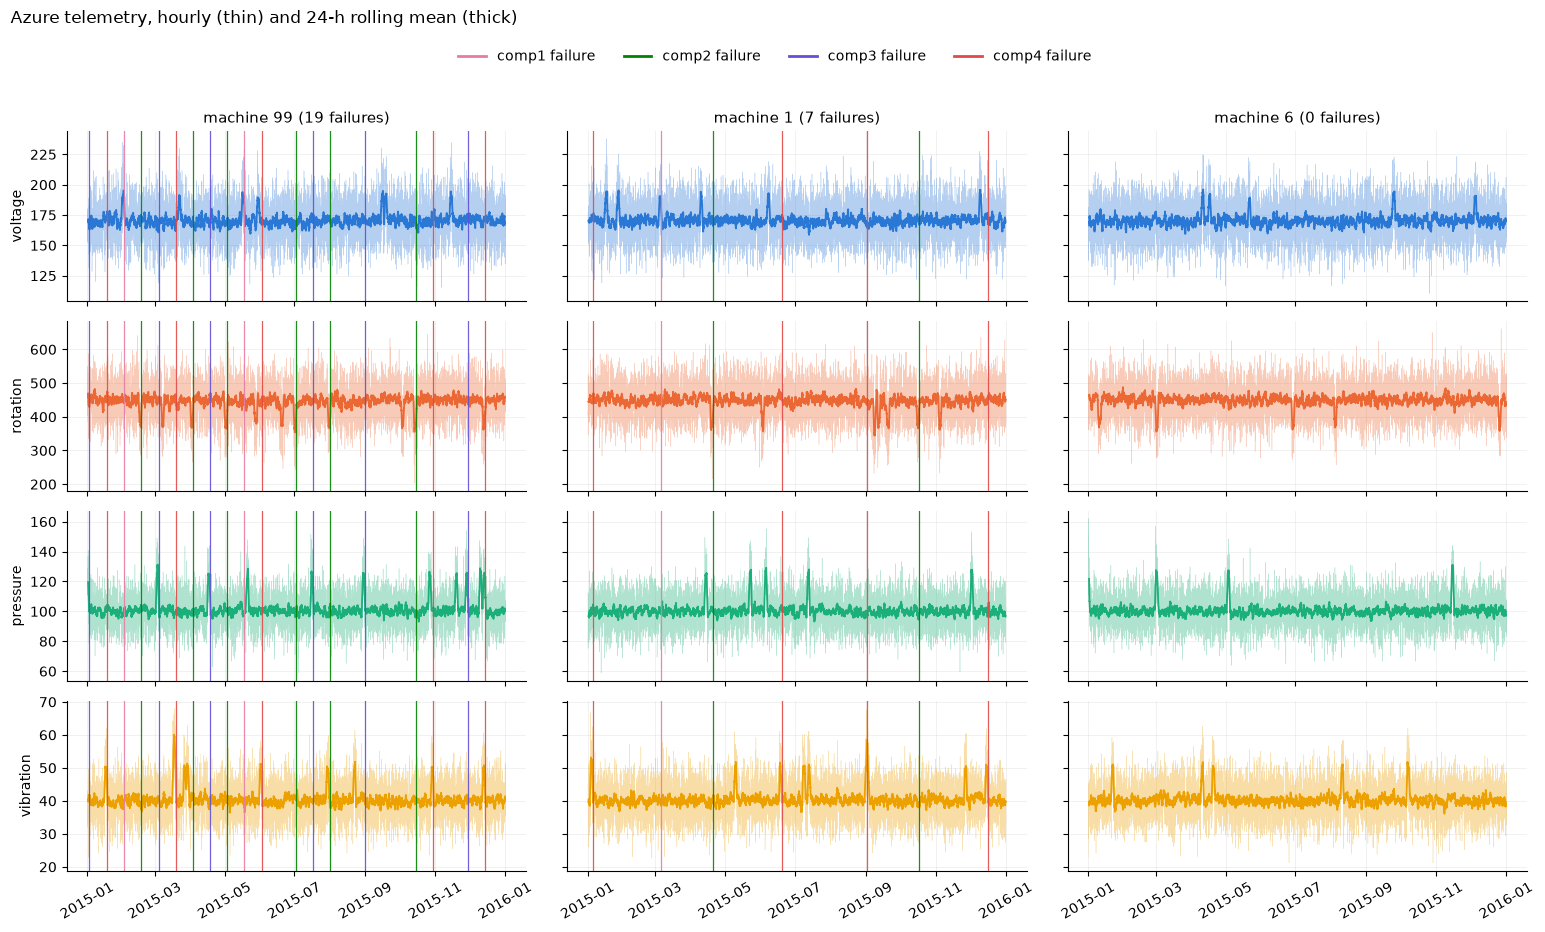

In [8]:
# Failures per machine, including machines with none (reindex fills missing machines with 0).
failures_per_machine = failures_raw.groupby("machineID").size().reindex(MACHINE_IDS, fill_value=0)

# Most failures, the first machine whose count equals the median, and the fewest.
typical = failures_per_machine.index[failures_per_machine == int(failures_per_machine.median())][0]
EXAMPLE_MACHINES = list(dict.fromkeys(
    [failures_per_machine.idxmax(), typical, failures_per_machine.idxmin()]
))  # dict.fromkeys removes duplicates but keeps the order
print({int(m): int(failures_per_machine[m]) for m in EXAMPLE_MACHINES}, "(machine: failures)")


def plot_overview(machine_ids, path=None):
    """Grid of sensors (rows) x machines (columns): hourly values, 24-h rolling mean and failure times."""
    fig, axes = plt.subplots(NUM_SENSORS, len(machine_ids), figsize=(5.2 * len(machine_ids), 9),
                             sharex=True, sharey="row")  # same y-range for one sensor across machines
    axes = np.atleast_2d(axes).reshape(NUM_SENSORS, len(machine_ids))
    for col, mid in enumerate(machine_ids):
        rows, events = machine_history(mid)
        for row, (azure_name, name) in enumerate(AZURE_TO_CONFIG.items()):
            ax = axes[row, col]
            series = rows.set_index("datetime")[azure_name]
            ax.plot(series.index, series, color=SENSOR_COLORS[name], linewidth=0.3, alpha=0.35)
            # center=True: the mean of the 24 hours around each point, so the smooth line is not shifted in time.
            ax.plot(series.index, series.rolling(24, center=True).mean(), color=SENSOR_COLORS[name], linewidth=1.3)
            for _, ev in events.iterrows():
                ax.axvline(ev["datetime"], color=COMPONENT_COLORS[ev["failure"]], linewidth=0.9, alpha=0.9)
            if col == 0:
                ax.set_ylabel(name)
        axes[0, col].set_title(f"machine {mid} ({len(events)} failures)", fontsize=11)
    for ax in axes[-1]:
        ax.tick_params(axis="x", labelrotation=30)
    # Legend for the failure lines, once for the whole figure.
    handles = [plt.Line2D([], [], color=COMPONENT_COLORS[c], linewidth=2) for c in COMPONENTS]
    fig.legend(handles, [f"{c} failure" for c in COMPONENTS], loc="upper center", ncol=4, frameon=False,
               bbox_to_anchor=(0.5, 1.0))
    fig.suptitle("Azure telemetry, hourly (thin) and 24-h rolling mean (thick)", x=0.01, ha="left", y=1.03)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    if path is not None:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


plot_overview(EXAMPLE_MACHINES, path=FIGURES_DIR / "azure_sensor_overview.png")

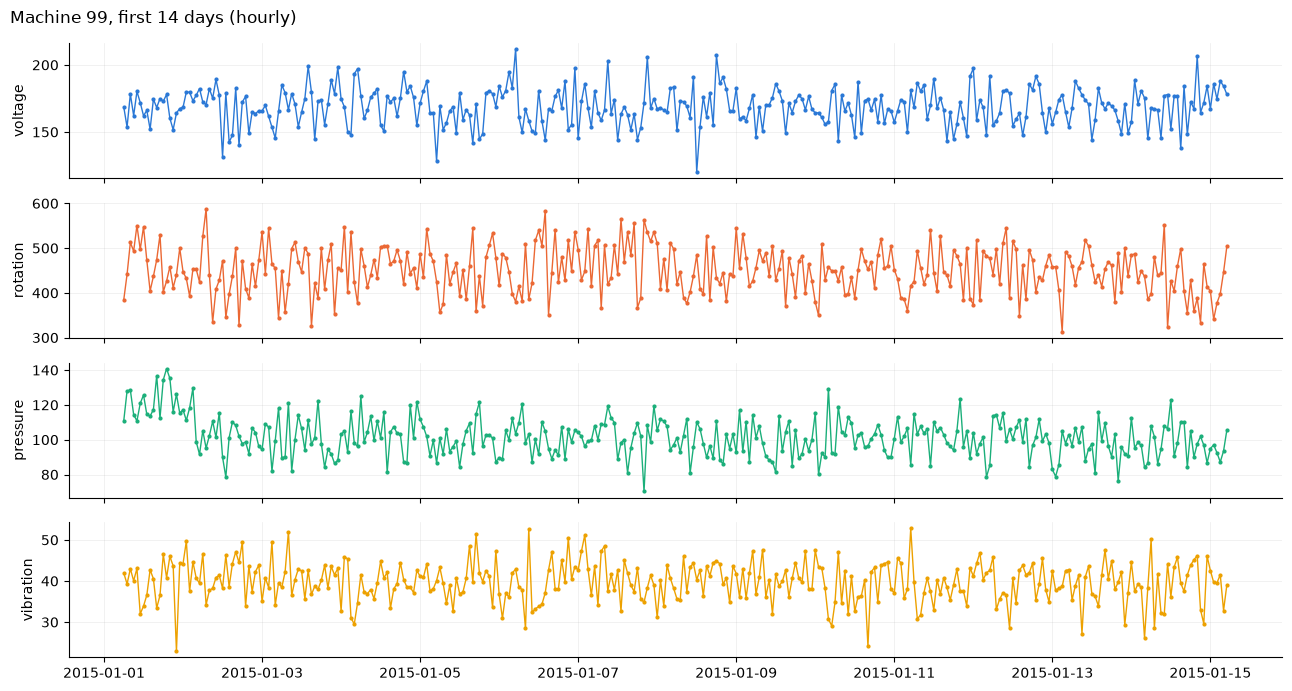

In [9]:
# Zoom: two weeks of the first example machine, where individual hourly movements are visible.
rows, events = machine_history(EXAMPLE_MACHINES[0])
two_weeks = rows[rows["datetime"] < T0 + pd.Timedelta(days=14)].set_index("datetime")
fig, axes = plt.subplots(NUM_SENSORS, 1, figsize=(13, 7), sharex=True)
for ax, (azure_name, name) in zip(axes, AZURE_TO_CONFIG.items()):
    ax.plot(two_weeks.index, two_weeks[azure_name], color=SENSOR_COLORS[name], linewidth=1, marker="o", markersize=2)
    ax.set_ylabel(name)
fig.suptitle(f"Machine {EXAMPLE_MACHINES[0]}, first 14 days (hourly)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [10]:
# --- Descriptive statistics (all machines, whole year, original units) ----------------------
print("Descriptive statistics:")
display(telemetry_raw[AZURE_SENSORS].describe().T.round(2))

# Do machines differ in their typical level? Compare the spread of per-machine means with the
# spread of all hourly readings. A small ratio means machines share roughly the same operating level.
machine_means = telemetry_raw.groupby("machineID")[AZURE_SENSORS].mean()
display(pd.DataFrame({
    "std of machine means": machine_means.std(),
    "std of hourly readings": telemetry_raw[AZURE_SENSORS].std(),
    "ratio": machine_means.std() / telemetry_raw[AZURE_SENSORS].std(),
}).round(3))

# --- Correlation between sensors at the same hour --------------------------------------------
# Pooled over all machines, and averaged over per-machine correlation matrices
# (the pooled value can be distorted by differences in level between machines).
print("Sensor correlation (pooled):")
display(telemetry_raw[AZURE_SENSORS].corr().round(3))
print("Sensor correlation (mean of per-machine matrices):")
display(telemetry_raw.groupby("machineID")[AZURE_SENSORS].corr().groupby(level=1).mean()
        .loc[AZURE_SENSORS, AZURE_SENSORS].round(3))

# --- Temporal dependence ------------------------------------------------------------------------
# Autocorrelation at lag k = correlation between a reading and the reading k hours earlier, per machine,
# then the median over the 100 machines. Lag 6 is one block, lag 24 one day.
lags = (1, 6, 24)
acf = {
    f"lag {k} h": [telemetry_raw.groupby("machineID")[s].apply(lambda x: x.autocorr(k)).median() for s in AZURE_SENSORS]
    for k in lags
}
print("Median per-machine autocorrelation:")
display(pd.DataFrame(acf, index=AZURE_SENSORS).round(3))

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
volt,876100.0,170.78,15.51,97.33,160.30,170.61,181.00,255.12
rotate,876100.0,446.61,52.67,138.43,412.31,447.56,482.18,695.02
pressure,876100.0,100.86,11.05,51.24,93.50,100.43,107.56,185.95
vibration,876100.0,40.39,5.37,14.88,36.78,40.24,43.78,76.79


,std of machine means,std of hourly readings,ratio
volt,0.190,15.509,0.012
rotate,0.814,52.674,0.015
pressure,0.309,11.049,0.028
vibration,0.124,5.370,0.023


Sensor correlation (pooled):


,volt,rotate,pressure,vibration
volt,1.000,-0.002,0.002,0.002
rotate,-0.002,1.000,-0.001,-0.003
pressure,0.002,-0.001,1.000,0.001
vibration,0.002,-0.003,0.001,1.000


Sensor correlation (mean of per-machine matrices):


,volt,rotate,pressure,vibration
volt,1.000,-0.002,0.002,0.002
rotate,-0.002,1.000,-0.001,-0.003
pressure,0.002,-0.001,1.000,0.001
vibration,0.002,-0.003,0.001,1.000


Median per-machine autocorrelation:


,lag 1 h,lag 6 h,lag 24 h
volt,0.063,0.056,0.030
rotate,0.093,0.084,0.048
pressure,0.156,0.138,0.079
vibration,0.120,0.102,0.061


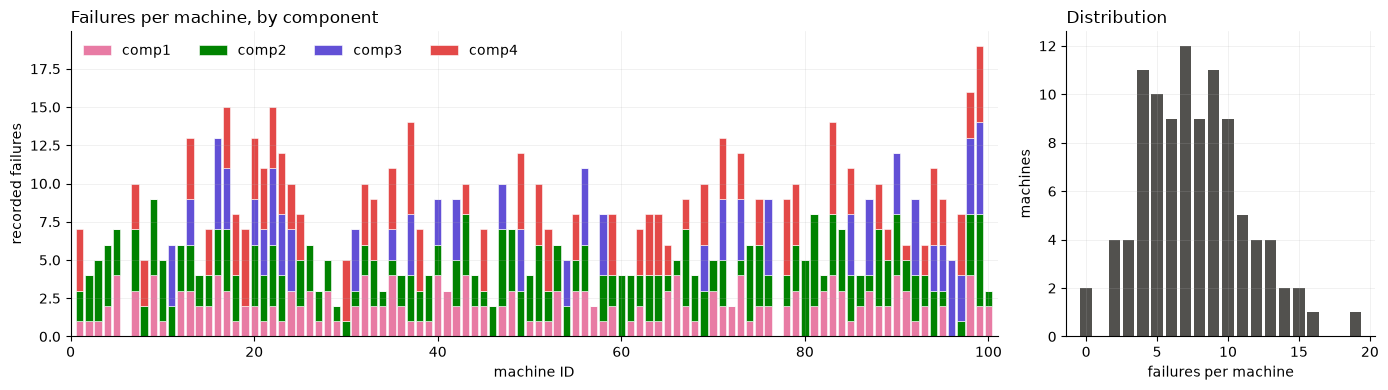

failure,comp1,comp2,comp3,comp4
total failures,192,259,131,179


In [11]:
# --- Failures per machine and component ---------------------------------------------------------
# crosstab counts rows for every (machine, component) pair; reindex adds machines without failures.
counts = pd.crosstab(failures_raw["machineID"], failures_raw["failure"]).reindex(MACHINE_IDS, fill_value=0)

fig, (ax_bar, ax_hist) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})
bottom = np.zeros(len(counts))
for comp in COMPONENTS:  # stacked bars: each component sits on top of the previous ones
    ax_bar.bar(counts.index, counts[comp], bottom=bottom, color=COMPONENT_COLORS[comp], width=0.8,
               edgecolor="white", linewidth=0.4, label=comp)
    bottom += counts[comp].to_numpy()
ax_bar.set_xlabel("machine ID")
ax_bar.set_ylabel("recorded failures")
ax_bar.set_xlim(0, len(counts) + 1)
ax_bar.legend(ncol=4, frameon=False, loc="upper left")
ax_bar.set_title("Failures per machine, by component", loc="left")

# How many machines have 0, 1, 2, ... failures.
per_machine_counts = failures_per_machine.value_counts().sort_index()
ax_hist.bar(per_machine_counts.index, per_machine_counts.values, color="#52514e", width=0.8)
ax_hist.set_xlabel("failures per machine")
ax_hist.set_ylabel("machines")
ax_hist.set_title("Distribution", loc="left")
fig.tight_layout()
plt.show()

display(counts.sum().to_frame("total failures").T)

### Telemetry around recorded failures

One example per component: the 48 hours before and 24 hours after a failure, in original units. Hour 0 is the recorded failure time. The examples are failures where only that component failed, so each panel shows one component.

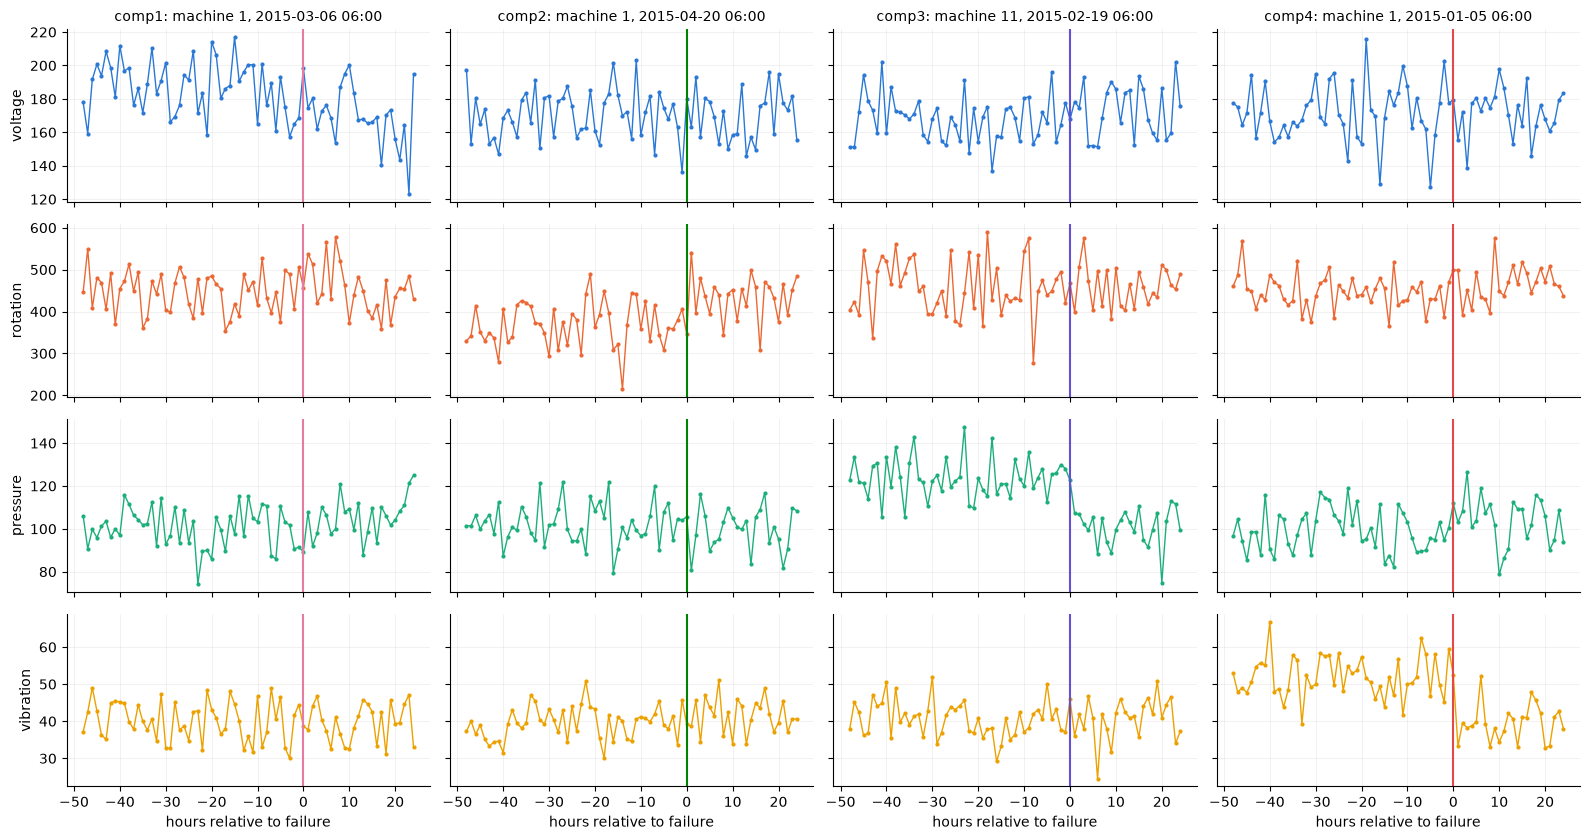

In [12]:
# A dense array cube[machine, hour, sensor] makes "the readings of machine m at hours h1..h2"
# a single indexing operation. Machines without a reading at some hour would hold NaN there.
def make_cube(frame, machine_col, columns, fill=np.nan):
    """Place frame[columns] into an array [n_machines, N_TIMESTAMPS, len(columns)] indexed by (machine, hour since T0)."""
    cube = np.full((len(MACHINE_IDS), N_TIMESTAMPS, len(columns)), fill)
    m = np.searchsorted(MACHINE_IDS, frame[machine_col].to_numpy())  # machine ID -> row position
    h = (frame["datetime"].to_numpy() - T0.to_datetime64()) // np.timedelta64(1, "h")  # hours since T0
    cube[m, h] = frame[columns].to_numpy()
    return cube


raw_cube = make_cube(telemetry_raw, "machineID", AZURE_SENSORS)  # [100, 8761, 4], original units
BEFORE, AFTER = 48, 24
offsets = np.arange(-BEFORE, AFTER + 1)  # -48 .. +24 hours relative to the failure


def event_window(cube, machine_id, time, offsets=offsets):
    """Readings of one machine at `time + offsets` hours (default -48 .. +24); NaN where outside the data."""
    h = (time - T0) // HOUR + offsets
    valid = (h >= 0) & (h < N_TIMESTAMPS)
    out = np.full((len(offsets), cube.shape[2]), np.nan)
    out[valid] = cube[np.searchsorted(MACHINE_IDS, machine_id), h[valid]]
    return out


# For each component, the first failure where that component failed alone and the full window exists.
single = failures_raw[~same_time]
examples = {
    comp: single[(single["failure"] == comp) & (single["datetime"] - T0 >= BEFORE * HOUR)
                 & (T_LAST - single["datetime"] >= AFTER * HOUR)].iloc[0]
    for comp in COMPONENTS
}

fig, axes = plt.subplots(NUM_SENSORS, len(COMPONENTS), figsize=(16, 8.5), sharex=True, sharey="row")
for col, (comp, ev) in enumerate(examples.items()):
    window = event_window(raw_cube, ev["machineID"], ev["datetime"])
    for row, name in enumerate(SENSORS):
        ax = axes[row, col]
        ax.plot(offsets, window[:, row], color=SENSOR_COLORS[name], linewidth=1, marker="o", markersize=2)
        ax.axvline(0, color=COMPONENT_COLORS[comp], linewidth=1.5)
        if col == 0:
            ax.set_ylabel(name)
    axes[0, col].set_title(f"{comp}: machine {ev['machineID']}, {ev['datetime']:%Y-%m-%d %H:%M}", fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel("hours relative to failure")
fig.tight_layout()
plt.show()

Single examples are noisy. To see whether any pattern is **systematic**, we average a window around every recorded failure of each component. The window starts 96 h before the failure (rather than 48 h), so we can see where a shift begins.

To make machines comparable, each reading is expressed as a z-score relative to *that machine's* whole-year mean and standard deviation. This is purely exploratory: these statistics use all of 2015 and are never used to prepare model inputs. The model's normalization (Step 1.5) is fitted on the training period only.

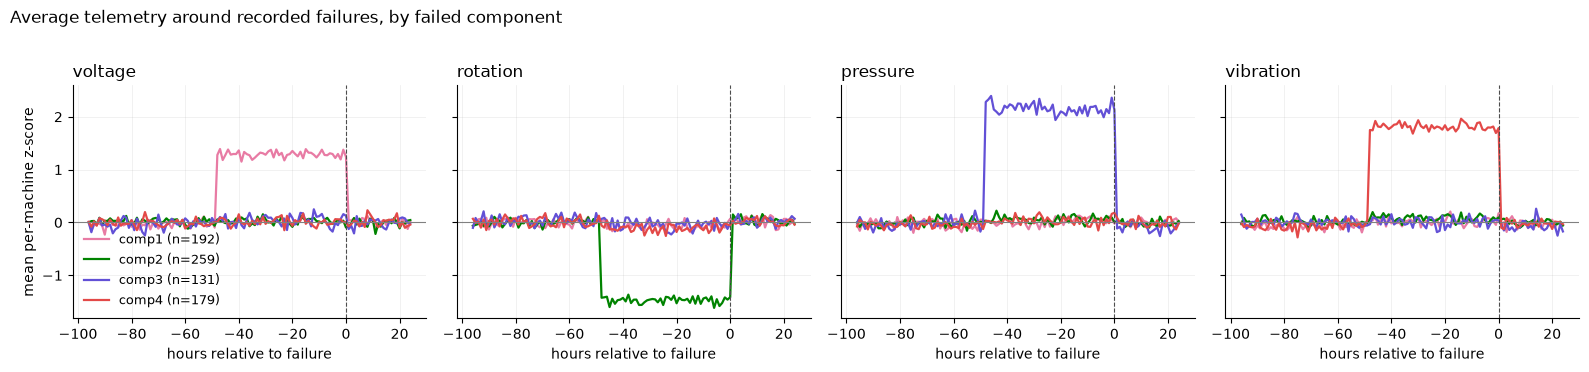

In [13]:
# Per-machine z-scores over the whole year (exploration only). nanmean/nanstd ignore missing hours.
machine_mu = np.nanmean(raw_cube, axis=1, keepdims=True)    # [100, 1, 4]
machine_sd = np.nanstd(raw_cube, axis=1, keepdims=True)
z_cube = (raw_cube - machine_mu) / machine_sd
long_offsets = np.arange(-96, AFTER + 1)  # -96 .. +24 hours

fig, axes = plt.subplots(1, NUM_SENSORS, figsize=(16, 3.6), sharey=True)
for comp in COMPONENTS:
    events = failures_raw[failures_raw["failure"] == comp]
    # Stack one [121, 4] window per failure -> [n_failures, 121, 4], then average over failures.
    stacked = np.stack([event_window(z_cube, m, t, long_offsets) for m, t in zip(events["machineID"], events["datetime"])])
    mean_window = np.nanmean(stacked, axis=0)
    for j, ax in enumerate(axes):
        ax.plot(long_offsets, mean_window[:, j], color=COMPONENT_COLORS[comp], linewidth=1.6,
                label=f"{comp} (n={len(events)})")
for ax, name in zip(axes, SENSORS):
    ax.axhline(0, color="0.5", linewidth=0.8)
    ax.axvline(0, color="0.3", linewidth=0.8, linestyle="--")
    ax.set_title(name, loc="left")
    ax.set_xlabel("hours relative to failure")
axes[0].set_ylabel("mean per-machine z-score")
axes[0].legend(frameon=False, fontsize=9, loc="lower left")
fig.suptitle("Average telemetry around recorded failures, by failed component", x=0.01, ha="left", y=1.02)
fig.tight_layout()
plt.show()

**Questions to answer from the figures and tables above**

- *Continuous per-machine sequences?* Yes. All 100 machines have 8,761 hourly rows from 2015-01-01 06:00 to 2016-01-01 06:00, with no missing hours, duplicates or NaNs.
- *Trends, regimes, differences between machines?* None that are visible over the year. Each sensor fluctuates around a stable level, and machines are almost identical: the spread of per-machine means is only 1–3 % of the hourly spread.
- *How predictable is the next block?* Hardly at all, hour to hour. Lag-1 autocorrelation is only 0.06–0.16 and lag-6 (one block) 0.06–0.14. Same-hour correlations between sensors are ≈ 0. Unlike the synthetic data, most of each hourly reading is independent noise. The predictable structure lies in the occasional **multi-day level shifts** visible in the 24-h rolling means. Expect a high noise floor in prediction error during normal operation.
- *Failures:* 761 records on 98 of 100 machines (0–19 per machine). comp2 is the most frequent. 42 events have two components failing together. 743 failures are stamped 06:00 and 18 are stamped 03:00. 743 of 761 have a same-time replacement record in the maintenance table.
- *Anything before failures?* In this simulation, yes, on average. Before a component failure, one sensor shifts: comp1 → voltage up (≈ +1.3 sd), comp2 → rotation down (≈ −1.5 sd), comp3 → pressure up (≈ +2.2 sd), comp4 → vibration up (≈ +1.8 sd). The other sensors stay at baseline.
  - The shift is an **abrupt step about 48 hours before** the recorded failure. It stays flat until the failure timestamp. The reading stamped *at* the failure time is still shifted, and the next hour is back to normal (the same-time replacement).
  - Caveat for Stage 5: the plateau (≈ 48 h) is longer than the 24-h context. Once the context lies inside the plateau, the shifted level is predictable from the context. Surprise is therefore more likely to peak near the **onset**, about two days before the failure record, than at the failure itself.
  - Individual failures are much noisier than the average, so not every failure will stand out.
- *Every excursion a failure?* No. Machine 6 has no recorded failures, yet its 24-h means show several multi-day excursions similar to the pre-failure shifts. Elevated surprise without a matching failure record is therefore not automatically a model error.

These are descriptive observations about a simulated dataset. They motivate the Stage 5 analysis but do not replace it.

## Step 1.3 — Clean and organize the telemetry

All cleaning works on a **copy**; `telemetry_raw` stays untouched.

Decisions, applied in this order (each logs how many rows it removed):

1. Rename columns to the config names (`machineID` → `machine_id`, `volt` → `voltage`, …) and sort by machine, then time.
2. Remove exact duplicate rows (same machine, time *and* values): one copy is kept.
3. Remove **every** copy of a machine–timestamp pair whose duplicates disagree. We cannot tell which value is right, so that hour is treated as missing.
4. Remove rows with a non-finite sensor value (NaN, ±inf) or a timestamp that is not on a whole hour.
5. Split each machine's history into **continuous segments**. A new segment starts wherever two consecutive rows are not exactly one hour apart. We never pretend the next observation after a gap came one hour later.

Missing values in the source data are handled here, by segmentation. The controlled dropouts of Stage 4 are a separate mechanism, applied later through the availability masks.

In [14]:
telemetry = (
    telemetry_raw.rename(columns={"machineID": "machine_id", **AZURE_TO_CONFIG})
    .sort_values(["machine_id", "datetime"], kind="stable")  # stable: equal keys keep their file order
    .reset_index(drop=True)
)
cleaning_log = [("source rows", len(telemetry), 0)]


def log_step(description, keep):
    """Keep the rows where `keep` is True and record how many were removed."""
    global telemetry
    removed = int((~keep).sum())
    telemetry = telemetry[keep].reset_index(drop=True)
    cleaning_log.append((description, len(telemetry), removed))


log_step("exact duplicate rows", ~telemetry.duplicated())
log_step("conflicting machine–timestamp duplicates", ~telemetry.duplicated(["machine_id", "datetime"], keep=False))
log_step("non-finite sensor values", np.isfinite(telemetry[SENSORS].to_numpy()).all(axis=1))
log_step("timestamps not on a whole hour", telemetry["datetime"] == telemetry["datetime"].dt.floor("h"))
display(pd.DataFrame(cleaning_log, columns=["step", "rows after", "rows removed"]))

# --- Continuous segments -----------------------------------------------------------------------------
# step = time since the previous row of the SAME machine (NaT for each machine's first row).
step = telemetry.groupby("machine_id")["datetime"].diff()
new_segment = step.isna() | (step != HOUR)              # first row of a machine, or a gap before this row
telemetry["segment_id"] = new_segment.cumsum() - 1      # 0, 1, 2, ... unique across all machines

gaps = telemetry.loc[step.notna() & (step != HOUR), ["machine_id", "datetime"]].assign(
    gap_before=step[step.notna() & (step != HOUR)]
)
segments = telemetry.groupby("segment_id").agg(
    machine_id=("machine_id", "first"), start=("datetime", "min"), end=("datetime", "max"), hours=("datetime", "size")
)
print(f"Gaps found (consecutive rows of a machine not 1 h apart): {len(gaps)}")
if len(gaps):
    display(gaps.head(20))
print(f"Continuous segments: {len(segments)} "
      f"(per machine: min {segments.groupby('machine_id').size().min()}, max {segments.groupby('machine_id').size().max()})")
print(f"Segment length (hours): min {segments['hours'].min():,}, max {segments['hours'].max():,}")

# Inside every segment, consecutive rows are exactly one hour apart and all values are finite.
within = telemetry.groupby("segment_id")["datetime"].diff().dropna()
assert (within == HOUR).all()
assert np.isfinite(telemetry[SENSORS].to_numpy()).all()
display(telemetry.head())

,step,rows after,rows removed
0,source rows,876100,0
1,exact duplicate rows,876100,0
2,conflicting machine–timestamp duplicates,876100,0
3,non-finite sensor values,876100,0
4,timestamps not on a whole hour,876100,0


Gaps found (consecutive rows of a machine not 1 h apart): 0
Continuous segments: 100 (per machine: min 1, max 1)
Segment length (hours): min 8,761, max 8,761


,datetime,machine_id,voltage,rotation,pressure,vibration,segment_id
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686,0
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973,0
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847,0
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144,0
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511,0


## Step 1.4 — Split the dataset chronologically

The **raw hourly timestamps** are split first, with the same two cutoffs for every machine. Blocks and windows are then built inside each partition, so no window can contain hours from two partitions. Overlapping windows are never split at random.

The cutoffs sit on the 6-hour block grid (00:00, 06:00, 12:00, 18:00), so no block is cut in half by a boundary. The grid runs from the first grid point at or after the first timestamp to the end of the last *complete* block. 70 % / 15 % / 15 % of the grid's blocks gives the cutoffs.

All three partitions contain the same 100 machines, observed in different periods (no held-out machines in this first experiment).

In [15]:
first_time, last_time = telemetry["datetime"].min(), telemetry["datetime"].max()
GRID_START = first_time.ceil(BLOCK_FREQ)          # first block boundary at or after the first reading
GRID_END = (last_time + HOUR).floor(BLOCK_FREQ)   # exclusive end of the last complete block
n_grid_blocks = (GRID_END - GRID_START) // BLOCK   # blocks per machine on the grid

n_train_blocks = round(SPLIT_FRACTIONS["train"] * n_grid_blocks)
n_val_blocks = round(SPLIT_FRACTIONS["val"] * n_grid_blocks)
TRAIN_END = GRID_START + n_train_blocks * BLOCK
VAL_END = TRAIN_END + n_val_blocks * BLOCK

# Half-open intervals [start, end): a timestamp equal to `end` belongs to the next partition.
SPLITS = {"train": (GRID_START, TRAIN_END), "val": (TRAIN_END, VAL_END), "test": (VAL_END, GRID_END)}


def assign_partition(times):
    """Label each timestamp train / val / test by the cutoffs, or 'outside' if it lies outside the grid."""
    times = pd.Series(times)
    conditions = [(times >= start) & (times < end) for start, end in SPLITS.values()]
    return np.select(conditions, PARTITIONS, default="outside")


telemetry["partition"] = assign_partition(telemetry["datetime"])
outside = telemetry["partition"] == "outside"
print(f"Hourly rows outside the block grid (cannot form a complete block): {outside.sum()} "
      f"at {sorted(telemetry.loc[outside, 'datetime'].unique().astype(str))}")
log_step("outside the 6-hour block grid", ~outside)

# Event tables with the same labels. They stay separate from the sensor data.
failures = failures_raw.rename(columns={"machineID": "machine_id", "failure": "component"})
failures["partition"] = assign_partition(failures["datetime"])
maintenance = maint_raw.rename(columns={"machineID": "machine_id", "comp": "component"})
maintenance["partition"] = assign_partition(maintenance["datetime"])  # 2014 records -> 'outside'
errors = errors_raw.rename(columns={"machineID": "machine_id", "errorID": "error"})
errors["partition"] = assign_partition(errors["datetime"])

split_table = pd.DataFrame(
    {
        "start": [s for s, _ in SPLITS.values()],
        "end (exclusive)": [e for _, e in SPLITS.values()],
        "days": [(e - s) / pd.Timedelta(days=1) for s, e in SPLITS.values()],
        "blocks per machine": [(e - s) // BLOCK for s, e in SPLITS.values()],
        "hourly rows": [int((telemetry["partition"] == p).sum()) for p in PARTITIONS],
        "machines": [telemetry.loc[telemetry["partition"] == p, "machine_id"].nunique() for p in PARTITIONS],
        "failures": [int((failures["partition"] == p).sum()) for p in PARTITIONS],
        "machines with a failure": [failures.loc[failures["partition"] == p, "machine_id"].nunique() for p in PARTITIONS],
        "maintenance": [int((maintenance["partition"] == p).sum()) for p in PARTITIONS],
    },
    index=PARTITIONS,
)
display(split_table)
print("Failures per component and partition:")
display(pd.crosstab(failures["partition"], failures["component"]).reindex(PARTITIONS))

# Every partition must be a whole number of blocks; validation and test must contain every component's failures.
assert all((e - s) % BLOCK == pd.Timedelta(0) for s, e in SPLITS.values())
for p in ("val", "test"):
    assert set(failures.loc[failures["partition"] == p, "component"]) == set(COMPONENTS), p

Hourly rows outside the block grid (cannot form a complete block): 100 at ['2016-01-01 06:00:00']


,start,end (exclusive),days,blocks per machine,hourly rows,machines,failures,machines with a failure,maintenance
train,2015-01-01 06:00:00,2015-09-13 18:00:00,255.50,1022,613200,100,555,98,2020
val,2015-09-13 18:00:00,2015-11-07 12:00:00,54.75,219,131400,100,98,69,430
test,2015-11-07 12:00:00,2016-01-01 06:00:00,54.75,219,131400,100,108,70,429


Failures per component and partition:


component,comp1,comp2,comp3,comp4
partition,,,,
train,148,182,96,129
val,19,34,18,27
test,25,43,17,23


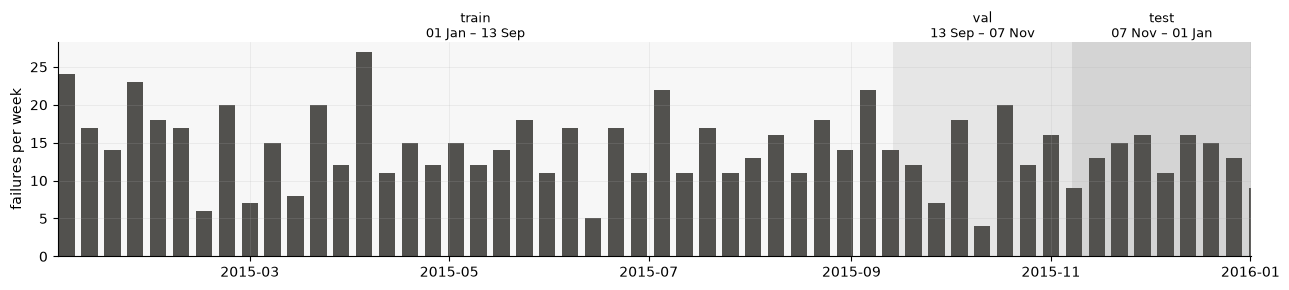

In [16]:
# Failures per week across the year, with the partitions shaded. Failures should be spread over
# the whole year, so the validation and test periods are not unusually quiet or busy.
weekly = failures.set_index("datetime").resample("W")["component"].size()
fig, ax = plt.subplots(figsize=(13, 3))
for (p, (start, end)), shade in zip(SPLITS.items(), ("0.97", "0.90", "0.83")):
    ax.axvspan(start, end, color=shade, linewidth=0, zorder=0)
    ax.text(start + (end - start) / 2, 1.0, f"{p}\n{start:%d %b} – {end:%d %b}", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=9)
ax.bar(weekly.index, weekly.values, width=5, color="#52514e")
ax.set_ylabel("failures per week")
ax.set_xlim(SPLITS["train"][0], SPLITS["test"][1])
fig.tight_layout()
plt.show()

## Step 1.5 — Normalize the sensor measurements

$$x'_{h,j}=\frac{x_{h,j}-\mu_j}{\sigma_j}$$

$\mu_j$ and $\sigma_j$ are fitted with Scikit-learn's `StandardScaler` on the **training rows only** (all 100 machines, training period). The same fitted scaler then transforms the training, validation and test rows. The cleaned telemetry in original units stays available in `telemetry`; the standardized copy is `telemetry_std`. The scaler is saved to `data/processed/scaler.pkl` in Step 1.9.

A standardized value of 0 means "equal to the training mean". This is why Stage 2 needs the availability mask: a missing reading filled with 0 would otherwise look exactly like a valid reading at the mean.

In [17]:
train_rows = telemetry["partition"] == "train"
# Fitting on a DataFrame records the column names (scaler.feature_names_in_), and sklearn will
# refuse to transform a table whose columns are in a different order.
scaler = StandardScaler().fit(telemetry.loc[train_rows, SENSORS])

telemetry_std = telemetry.copy()
telemetry_std[SENSORS] = scaler.transform(telemetry[SENSORS])

print(f"Scaler fitted on {int(scaler.n_samples_seen_):,} training rows:")
display(pd.DataFrame({"mean (mu_j)": scaler.mean_, "std (sigma_j)": scaler.scale_}, index=SENSORS).round(4))

# Mean / std of the standardized data per partition. Training is ~0 / ~1 by construction;
# validation and test need not be, and their deviations show how those periods differ from training.
stats = telemetry_std.groupby("partition")[SENSORS].agg(["mean", "std"]).reindex(PARTITIONS)
display(stats.T.unstack().round(3))
assert np.isfinite(telemetry_std[SENSORS].to_numpy()).all()

Scaler fitted on 613,200 training rows:


,mean (mu_j),std (sigma_j)
voltage,170.8019,15.5044
rotation,446.5952,52.6418
pressure,100.8107,11.0081
vibration,40.3976,5.3739


partition train         val          test       
           mean  std   mean    std   mean    std
voltage    -0.0  1.0 -0.003  0.999 -0.007  1.003
rotation    0.0  1.0  0.009  0.997 -0.008  1.007
pressure   -0.0  1.0  0.011  1.007  0.018  1.017
vibration   0.0  1.0 -0.006  1.001 -0.009  0.995

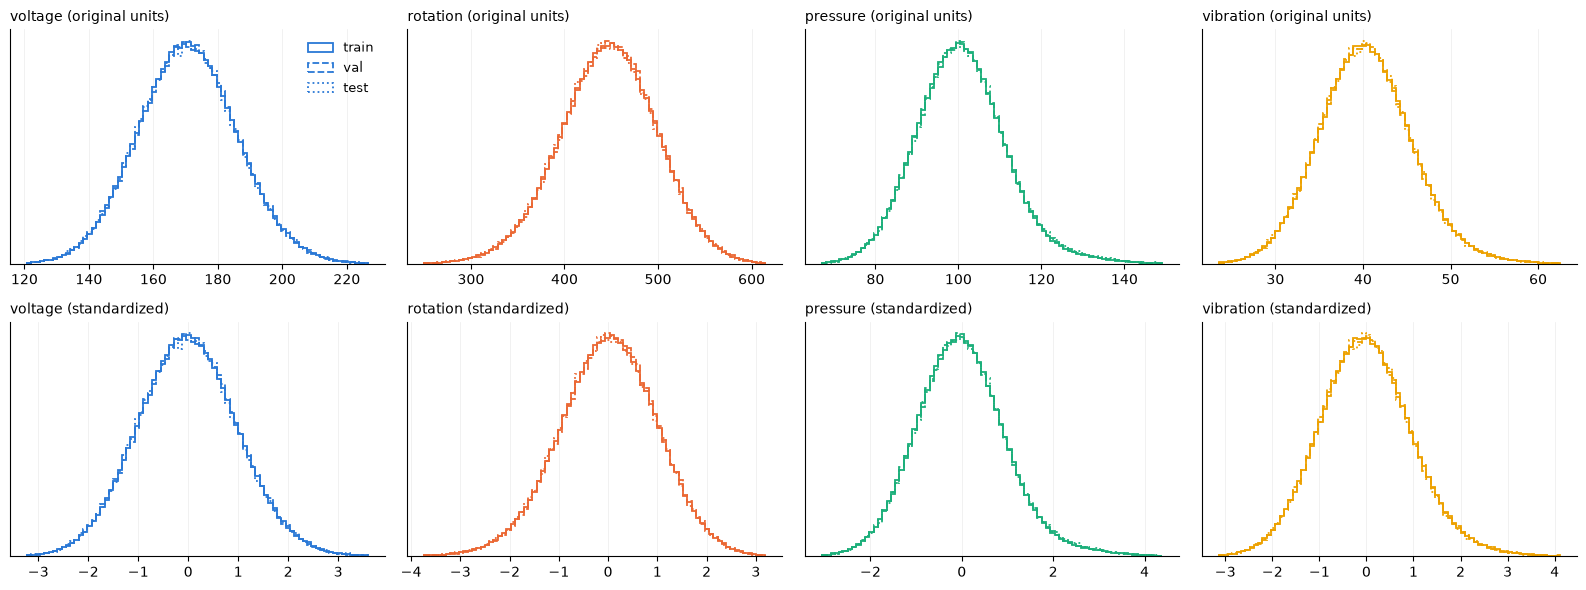

In [18]:
# Distributions before (top) and after (bottom) normalization; line style = partition.
# Standardization is a shift and a rescale, so the shapes are identical; only the axes change.
fig, axes = plt.subplots(2, NUM_SENSORS, figsize=(16, 6))
for j, name in enumerate(SENSORS):
    for row, frame in enumerate((telemetry, telemetry_std)):
        ax = axes[row, j]
        bins = np.linspace(*np.percentile(frame[name], [0.05, 99.95]), 80)
        for p in PARTITIONS:
            ax.hist(frame.loc[frame["partition"] == p, name], bins=bins, density=True, histtype="step",
                    color=SENSOR_COLORS[name], linestyle=PARTITION_STYLES[p], linewidth=1.3, label=p)
        ax.set_title(f"{name} ({'original units' if row == 0 else 'standardized'})", loc="left", fontsize=10)
        ax.set_yticks([])
axes[0, 0].legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## Step 1.6 — Construct 6-hour sensor blocks

A block is six consecutive hourly rows of one machine, on the shared clock grid: it starts at 00:00, 06:00, 12:00 or 18:00. Each block is

$$x_\tau\in\mathbb R^{6\times4}$$

Nothing is averaged: the encoder receives all 24 values, so transient behaviour within a block is preserved.

Every hourly row gets the start of its block (`datetime.floor("6h")`). A block is kept only if its (machine, partition, segment, block start) group has exactly six rows. Six distinct whole-hour timestamps inside one 6-hour interval must be all six consecutive hours. Blocks touched by a gap, or cut by the end of the data, are discarded.

Rows are already sorted by machine and time, so the kept rows can be reshaped directly into `[blocks, 6, 4]`.

In [19]:
def complete_block_rows(frame):
    """Return the rows of `frame` that belong to complete 6-hour blocks, plus the number of incomplete blocks."""
    frame = frame.assign(block_start=frame["datetime"].dt.floor(BLOCK_FREQ))
    keys = ["machine_id", "partition", "segment_id", "block_start"]
    rows_in_block = frame.groupby(keys)["datetime"].transform("size")  # block size, repeated on each of its rows
    # A gap inside a block splits it over two segments; count each (machine, block start) only once.
    n_incomplete = frame.loc[rows_in_block != BLOCK_SIZE, ["machine_id", "block_start"]].drop_duplicates().shape[0]
    return frame[rows_in_block == BLOCK_SIZE], n_incomplete


kept, n_incomplete_blocks = complete_block_rows(telemetry_std)
print(f"Incomplete blocks discarded: {n_incomplete_blocks}")

# reshape regroups rows 0-5, 6-11, ... into blocks without reordering anything.
blocks_norm = kept[SENSORS].to_numpy().reshape(-1, BLOCK_SIZE, NUM_SENSORS)                   # model input
blocks_raw = telemetry.loc[kept.index, SENSORS].to_numpy().reshape(-1, BLOCK_SIZE, NUM_SENSORS)  # original units, for inspection
block_hours = kept["datetime"].to_numpy().reshape(-1, BLOCK_SIZE)                                # timestamp of every row
block_machine = kept["machine_id"].to_numpy().reshape(-1, BLOCK_SIZE)

# One row per block (every 6th kept row is the first row of a block).
block_table = kept.iloc[::BLOCK_SIZE][["machine_id", "partition", "segment_id", "block_start"]].reset_index(drop=True)
block_table["block_end"] = block_table["block_start"] + BLOCK - HOUR  # timestamp of the block's last hourly row

# Each block: six rows of one machine, starting at its grid point, one hour apart.
assert (block_machine == block_machine[:, :1]).all()
assert (block_hours[:, 0] == block_table["block_start"].to_numpy()).all()
assert (np.diff(block_hours, axis=1) == np.timedelta64(1, "h")).all()

for p in PARTITIONS:
    sel = (block_table["partition"] == p).to_numpy()
    print(f"{p:5s} blocks: {blocks_norm[sel].shape}  ({sel.sum() // len(MACHINE_IDS)} per machine)")

Incomplete blocks discarded: 0
train blocks: (102200, 6, 4)  (1022 per machine)
val   blocks: (21900, 6, 4)  (219 per machine)
test  blocks: (21900, 6, 4)  (219 per machine)


In [20]:
# Expected per machine: floor(N / 6) for N hourly rows in a partition (when the data are complete).
m = EXAMPLE_MACHINES[0]
display(pd.DataFrame(
    {
        "hourly rows N": [int(((telemetry["machine_id"] == m) & (telemetry["partition"] == p)).sum()) for p in PARTITIONS],
        "blocks": [int(((block_table["machine_id"] == m) & (block_table["partition"] == p)).sum()) for p in PARTITIONS],
    },
    index=pd.Index(PARTITIONS, name=f"machine {m}"),
).assign(**{"floor(N / 6)": lambda d: d["hourly rows N"] // BLOCK_SIZE}))

# Compare the first block of that machine with its raw rows (original units).
b = int(np.flatnonzero(block_table["machine_id"] == m)[0])
print(f"Block {b}: machine {m}, {block_table.loc[b, 'block_start']} → {block_table.loc[b, 'block_end']}")
display(pd.DataFrame(blocks_raw[b], columns=SENSORS, index=pd.Index(block_hours[b], name="datetime")).round(3))
source = telemetry_raw[(telemetry_raw["machineID"] == m)
                       & telemetry_raw["datetime"].between(block_table.loc[b, "block_start"], block_table.loc[b, "block_end"])
                       ].sort_values("datetime")
assert np.array_equal(blocks_raw[b], source[AZURE_SENSORS].to_numpy())

,hourly rows N,blocks,floor(N / 6)
machine 99,,,
train,6132,1022,1022
val,1314,219,219
test,1314,219,219


Block 143080: machine 99, 2015-01-01 06:00:00 → 2015-01-01 11:00:00


,voltage,rotation,pressure,vibration
datetime,,,,
2015-01-01 06:00:00,168.596,384.747,110.921,41.945
2015-01-01 07:00:00,153.668,441.289,128.011,39.272
2015-01-01 08:00:00,178.319,512.613,128.526,42.975
2015-01-01 09:00:00,162.164,493.357,114.436,40.044
2015-01-01 10:00:00,180.201,550.512,110.772,43.055
2015-01-01 11:00:00,171.918,497.118,120.869,32.013


## Step 1.7 — Historical context and future targets

$$C_t=[x_{t-3},x_{t-2},x_{t-1},x_t]\in\mathbb R^{4\times6\times4},\qquad Y_t=x_{t+1}\in\mathbb R^{6\times4}$$

Windows are built from **runs** of consecutive blocks. A run is a maximal sequence of blocks with the same machine, partition and segment, whose start times step by exactly 6 hours. A new run starts at a machine change, a partition boundary, or any gap. The window slides by one block (6 h), and a run of $B$ blocks gives

$$N_{\text{windows}}=\max(0,\,B-4)$$

In vectorized form: every block at position ≥ 4 inside its run is a target, and its context is the four blocks just before it.

Sample order: train, then validation, then test. Within a partition, samples are ordered by machine and then by time. `sample_id` is unique across all partitions.

In [21]:
bt = block_table
new_run = (
    (bt["machine_id"] != bt["machine_id"].shift())
    | (bt["partition"] != bt["partition"].shift())
    | (bt["segment_id"] != bt["segment_id"].shift())
    | (bt["block_start"].diff() != BLOCK)          # NaT for the first row compares as "different" too
)
bt["run_id"] = new_run.cumsum() - 1
bt["position_in_run"] = bt.groupby("run_id").cumcount()  # 0, 1, 2, ... inside each run

# Every block with at least CONTEXT_LENGTH predecessors in its run is a target.
target_idx = np.flatnonzero(bt["position_in_run"].to_numpy() >= CONTEXT_LENGTH)
# Broadcasting [n, 1] + [4] -> [n, 4]: the four blocks right before each target, oldest first.
context_idx = target_idx[:, None] + np.arange(-CONTEXT_LENGTH, 0)

# Order: partition (train, val, test), then machine, then time.
# np.lexsort sorts by the LAST key first, so the keys are listed from least to most significant.
partition_rank = bt["partition"].map({p: i for i, p in enumerate(PARTITIONS)}).to_numpy()
order = np.lexsort((bt["block_start"].to_numpy()[target_idx], bt["machine_id"].to_numpy()[target_idx],
                    partition_rank[target_idx]))
target_idx, context_idx = target_idx[order], context_idx[order]

# The run sizes predict the number of windows exactly.
run_sizes = bt.groupby("run_id").size()
assert len(target_idx) == np.maximum(0, run_sizes - CONTEXT_LENGTH).sum()

window_metadata = pd.DataFrame({
    "sample_id": np.arange(len(target_idx)),
    "partition": bt["partition"].to_numpy()[target_idx],
    "machine_id": bt["machine_id"].to_numpy()[target_idx],
    "run_id": bt["run_id"].to_numpy()[target_idx],
    "context_start": bt["block_start"].to_numpy()[context_idx[:, 0]],   # first hour of the oldest context block
    "context_end": bt["block_end"].to_numpy()[context_idx[:, -1]],      # last hour of the newest context block
    "target_start": bt["block_start"].to_numpy()[target_idx],
    "target_end": bt["block_end"].to_numpy()[target_idx],               # last target hour: surprise is computable only after it
})
window_metadata["index_in_partition"] = window_metadata.groupby("partition").cumcount()

# Arrays per partition. Each sample's context and target come from the same run, hence one machine and partition.
windows = {}
for p in PARTITIONS:
    sel = (window_metadata["partition"] == p).to_numpy()
    windows[p] = {
        "context": blocks_norm[context_idx[sel]],        # [n, 4, 6, 4]
        "target": blocks_norm[target_idx[sel]],          # [n, 6, 4]
        "context_hours": block_hours[context_idx[sel]],  # [n, 4, 6]
        "target_hours": block_hours[target_idx[sel]],    # [n, 6]
        "metadata": window_metadata[sel].reset_index(drop=True),
    }
    print(f"{p:5s} context {windows[p]['context'].shape}   target {windows[p]['target'].shape}")

display(window_metadata.groupby("partition", sort=False).agg(
    samples=("sample_id", "size"), first_sample_id=("sample_id", "min"), last_sample_id=("sample_id", "max"),
    first_target_start=("target_start", "min"), last_target_end=("target_end", "max"),
))

train context (101800, 4, 6, 4)   target (101800, 6, 4)
val   context (21500, 4, 6, 4)   target (21500, 6, 4)
test  context (21500, 4, 6, 4)   target (21500, 6, 4)


,samples,first_sample_id,last_sample_id,first_target_start,last_target_end
partition,,,,,
train,101800,0,101799,2015-01-02 06:00:00,2015-09-13 17:00:00
val,21500,101800,123299,2015-09-14 18:00:00,2015-11-07 11:00:00
test,21500,123300,144799,2015-11-08 12:00:00,2016-01-01 05:00:00


In [22]:
# Inspect one sample: the first validation window of the first example machine, all five blocks in original units.
meta_val = windows["val"]["metadata"]
i = int(np.flatnonzero(meta_val["machine_id"] == EXAMPLE_MACHINES[0])[0])
sample_meta = meta_val.iloc[i]
g = int(sample_meta["sample_id"])  # row in context_idx / target_idx
labels = ["x_{t-3}", "x_{t-2}", "x_{t-1}", "x_t", "target x_{t+1}"]
five_blocks = list(context_idx[g]) + [target_idx[g]]
table = pd.concat(
    [pd.DataFrame(blocks_raw[b], columns=SENSORS)
       .assign(block=label, datetime=block_hours[b], machine_id=block_machine[b])
     for label, b in zip(labels, five_blocks)]
).set_index(["block", "datetime"])
print(sample_meta.to_string())
display(table.round(2))

hours30 = np.concatenate([windows["val"]["context_hours"][i].reshape(-1), windows["val"]["target_hours"][i]])
print(f"Context spans {(sample_meta['context_end'] - sample_meta['context_start']) + HOUR} "
      f"({CONTEXT_LENGTH * BLOCK_SIZE} hourly rows); target starts {sample_meta['target_start'] - sample_meta['context_end']} after the context ends")
assert (np.diff(hours30) == np.timedelta64(1, "h")).all()          # 30 consecutive hours, no gap
assert (table["machine_id"] == sample_meta["machine_id"]).all()     # one machine

sample_id                          122870
partition                             val
machine_id                             99
run_id                                295
context_start         2015-09-13 18:00:00
context_end           2015-09-14 17:00:00
target_start          2015-09-14 18:00:00
target_end            2015-09-14 23:00:00
index_in_partition                  21070


voltage  rotation  pressure  vibration  \
block          datetime                                                      
x_{t-3}        2015-09-13 18:00:00   186.71    456.52     97.02      41.29   
               2015-09-13 19:00:00   152.82    402.91    106.29      42.89   
               2015-09-13 20:00:00   148.02    380.85    116.33      39.39   
               2015-09-13 21:00:00   151.42    429.62     98.46      39.22   
               2015-09-13 22:00:00   143.86    477.55     92.03      36.34   
               2015-09-13 23:00:00   165.58    439.09    112.67      47.26   
x_{t-2}        2015-09-14 00:00:00   184.22    398.96    102.80      37.88   
               2015-09-14 01:00:00   178.56    489.83    105.87      40.08   
               2015-09-14 02:00:00   170.28    478.44    100.87      38.91   
               2015-09-14 03:00:00   146.22    409.34    102.45      33.69   
               2015-09-14 04:00:00   200.58    446.75    105.00      30.93   
               2015-09-14 05:00:00   166.63    494.15    113.29      29.54   
x_{t-1}        2015-09-14 06:00:00   154.35    457.95    105.28      36.99   
               2015-09-14 07:00:00   179.75    411.13     97.56      34.60   
               2015-09-14 08:00:00   177.22    442.32     90.60      33.58   
               2015-09-14 09:00:00   158.37    459.46    104.50      31.81   
               2015-09-14 10:00:00   190.40    517.91    103.47      32.01   
               2015-09-14 11:00:00   176.29    500.85    102.86      44.27   
x_t            2015-09-14 12:00:00   175.34    421.72     85.64      36.05   
               2015-09-14 13:00:00   164.41    453.53    112.93      35.26   
               2015-09-14 14:00:00   171.59    398.65    109.06      34.19   
               2015-09-14 15:00:00   153.04    435.06    108.25      48.49   
               2015-09-14 16:00:00   173.67    490.99    102.25      39.04   
               2015-09-14 17:00:00   164.35    420.43     93.68      38.42   
target x_{t+1} 2015-09-14 18:00:00   187.75    439.46     91.95      44.69   
               2015-09-14 19:00:00   218.09    519.51     94.16      41.31   
               2015-09-14 20:00:00   175.28    498.25     95.37      33.30   
               2015-09-14 21:00:00   230.02    454.18    112.71      40.55   
               2015-09-14 22:00:00   199.41    528.79    106.30      45.08   
               2015-09-14 23:00:00   193.16    432.37    101.37      40.78   

                                    machine_id  
block          datetime                         
x_{t-3}        2015-09-13 18:00:00          99  
               2015-09-13 19:00:00          99  
               2015-09-13 20:00:00          99  
               2015-09-13 21:00:00          99  
               2015-09-13 22:00:00          99  
               2015-09-13 23:00:00          99  
x_{t-2}        2015-09-14 00:00:00          99  
               2015-09-14 01:00:00          99  
               2015-09-14 02:00:00          99  
               2015-09-14 03:00:00          99  
               2015-09-14 04:00:00          99  
               2015-09-14 05:00:00          99  
x_{t-1}        2015-09-14 06:00:00          99  
               2015-09-14 07:00:00          99  
               2015-09-14 08:00:00          99  
               2015-09-14 09:00:00          99  
               2015-09-14 10:00:00          99  
               2015-09-14 11:00:00          99  
x_t            2015-09-14 12:00:00          99  
               2015-09-14 13:00:00          99  
               2015-09-14 14:00:00          99  
               2015-09-14 15:00:00          99  
               2015-09-14 16:00:00          99  
               2015-09-14 17:00:00          99  
target x_{t+1} 2015-09-14 18:00:00          99  
               2015-09-14 19:00:00          99  
               2015-09-14 20:00:00          99  
               2015-09-14 21:00:00          99  
               2015-09-14 22:00:00          99  
               2015-

Context spans 1 days 00:00:00 (24 hourly rows); target starts 0 days 01:00:00 after the context ends


## Step 1.8 — Availability masks, metadata and PyTorch DataLoaders

**Masks.** Every retained reading is present, so all masks are ones: $M_t=\mathbf 1^{4\times6\times4}$ and $m_{t+1}=\mathbf 1^{6\times4}$. Stage 4 will write zeros into the historical masks to simulate dropouts.

**Metadata.** Each sample carries `sample_id`, `machine_id`, `context_start`, `context_end`, `target_start`, `target_end`. Failure and maintenance records are **not** attached to the samples. They stay in their own tables (`failures`, `maintenance`) and are matched to `target_end` later.

**Tensors.** For each partition, the tensors are collected in a plain dict. Step 1.9 saves exactly this dict, so Stage 2 can rebuild the same `Dataset` from the saved file.

In [23]:
TIME_COLUMNS = ["context_start", "context_end", "target_start", "target_end"]

# The per-partition dict that is saved in Step 1.9 and reloaded in Stage 2.
tensors = {}
for p, w in windows.items():
    tensors[p] = {
        "context": torch.as_tensor(w["context"], dtype=torch.float32),               # [n, 4, 6, 4]
        "context_mask": torch.ones(w["context"].shape, dtype=torch.float32),          # [n, 4, 6, 4] all available
        "target": torch.as_tensor(w["target"], dtype=torch.float32),                  # [n, 6, 4]
        "target_mask": torch.ones(w["target"].shape, dtype=torch.float32),            # [n, 6, 4]
        # torch.tensor copies; pandas hands out read-only arrays, which torch.as_tensor would warn about.
        "sample_id": torch.tensor(w["metadata"]["sample_id"].to_numpy(), dtype=torch.int64),
        "machine_id": torch.tensor(w["metadata"]["machine_id"].to_numpy(), dtype=torch.int64),
        # Descriptive fields, so a reloaded file explains itself.
        "partition": p,
        "sensors": SENSORS,
    }


class AzureWindowDataset(Dataset):
    """Context/target windows of 6-hour Azure telemetry blocks from one chronological partition.

    tensors  : the dict built above (or reloaded from <partition>_windows.pt)
    metadata : the matching rows of window_metadata, in the same order
    Failure and maintenance events are deliberately NOT part of a sample.
    """

    def __init__(self, tensors, metadata):
        self.context = tensors["context"]
        self.context_mask = tensors["context_mask"]
        self.target = tensors["target"]
        self.target_mask = tensors["target_mask"]
        self.sample_id = tensors["sample_id"]
        self.machine_id = tensors["machine_id"]
        # The tensors and the metadata table must describe the same samples in the same order.
        assert torch.equal(self.sample_id, torch.tensor(metadata["sample_id"].to_numpy()))
        # Timestamps as plain strings: the DataLoader batches strings into lists, and they print readably.
        self.times = {c: pd.to_datetime(metadata[c]).dt.strftime(TIME_FORMAT).tolist() for c in TIME_COLUMNS}

    def __len__(self):
        return len(self.target)

    def __getitem__(self, i):
        return {
            "context": self.context[i],            # [4, 6, 4]
            "context_mask": self.context_mask[i],  # [4, 6, 4]
            "target": self.target[i],              # [6, 4]
            "target_mask": self.target_mask[i],    # [6, 4]
            "metadata": {
                "sample_id": self.sample_id[i],
                "machine_id": self.machine_id[i],
                **{c: self.times[c][i] for c in TIME_COLUMNS},
            },
        }


datasets = {p: AzureWindowDataset(tensors[p], windows[p]["metadata"]) for p in PARTITIONS}

# Only the training loader shuffles, and it shuffles COMPLETE windows; the hourly data were never shuffled.
# The seeded generator makes the shuffle order reproducible. Validation and test keep their order
# (machine, then time) so predictions can be traced back to machine and time.
loaders = {
    "train": DataLoader(datasets["train"], batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED)),
    "val": DataLoader(datasets["val"], batch_size=BATCH_SIZE, shuffle=False),
    "test": DataLoader(datasets["test"], batch_size=BATCH_SIZE, shuffle=False),
}

sample = datasets["train"][0]
print("One training sample:")
for key in ("context", "context_mask", "target", "target_mask"):
    print(f"  {key:13s} {tuple(sample[key].shape)} {sample[key].dtype}")
print(f"  metadata      {sample['metadata']}")

batch = next(iter(loaders["train"]))
print("\nOne training batch:")
for key in ("context", "context_mask", "target", "target_mask"):
    print(f"  {key:13s} {tuple(batch[key].shape)} {batch[key].dtype}")
print(f"  sample ids    {batch['metadata']['sample_id'][:6].tolist()} ... (shuffled)")
print(f"  machine ids   {batch['metadata']['machine_id'][:6].tolist()} ...")

val_batch = next(iter(loaders["val"]))
print(f"\nFirst validation batch, target_end: {val_batch['metadata']['target_end'][:3]} ... (chronological per machine)")
for p in PARTITIONS:
    n = len(datasets[p])
    print(f"{p:5s} {n:7,} samples -> {len(loaders[p]):4d} batches, last batch {n - (len(loaders[p]) - 1) * BATCH_SIZE} samples")

One training sample:
  context       (4, 6, 4) torch.float32
  context_mask  (4, 6, 4) torch.float32
  target        (6, 4) torch.float32
  target_mask   (6, 4) torch.float32
  metadata      {'sample_id': tensor(0), 'machine_id': tensor(1), 'context_start': '2015-01-01 06:00:00', 'context_end': '2015-01-02 05:00:00', 'target_start': '2015-01-02 06:00:00', 'target_end': '2015-01-02 11:00:00'}

One training batch:
  context       (128, 4, 6, 4) torch.float32
  context_mask  (128, 4, 6, 4) torch.float32
  target        (128, 6, 4) torch.float32
  target_mask   (128, 6, 4) torch.float32
  sample ids    [67720, 100872, 70121, 2820, 35049, 2835] ... (shuffled)
  machine ids   [67, 100, 69, 3, 35, 3] ...

First validation batch, target_end: ['2015-09-14 23:00:00', '2015-09-15 05:00:00', '2015-09-15 11:00:00'] ... (chronological per machine)
train 101,800 samples ->  796 batches, last batch 40 samples
val    21,500 samples ->  168 batches, last batch 124 samples
test   21,500 samples ->  168 b

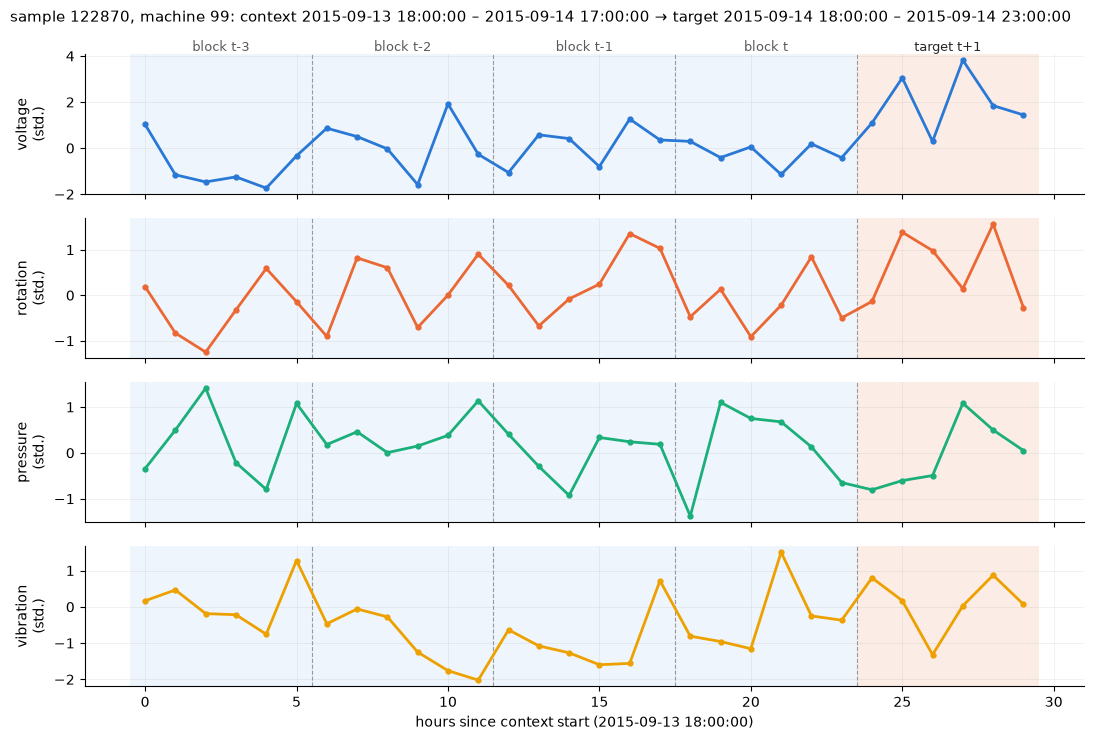

In [24]:
def plot_window(dataset, i, path=None):
    """Plot sample i of a Dataset: four context blocks (blue background) and the target block (orange)."""
    item = dataset[i]
    meta = item["metadata"]
    series = torch.cat([item["context"].reshape(-1, NUM_SENSORS), item["target"]]).numpy()  # [30, 4] standardized
    hour_axis = np.arange(len(series))
    target_start = CONTEXT_LENGTH * BLOCK_SIZE  # hour 24

    fig, axes = plt.subplots(NUM_SENSORS, 1, figsize=(11, 7.5), sharex=True)
    for j, (ax, name) in enumerate(zip(axes, SENSORS)):
        ax.axvspan(-0.5, target_start - 0.5, color="#2a78d6", alpha=0.07, linewidth=0)
        ax.axvspan(target_start - 0.5, hour_axis[-1] + 0.5, color="#eb6834", alpha=0.12, linewidth=0)
        for b in range(1, CONTEXT_LENGTH + 1):
            ax.axvline(b * BLOCK_SIZE - 0.5, color="0.6", linewidth=0.8, linestyle="--")
        ax.plot(hour_axis, series[:, j], color=SENSOR_COLORS[name], linewidth=2, marker="o", markersize=3.5)
        ax.set_ylabel(f"{name}\n(std.)")
    labels = [f"block t{-k}" if k else "block t" for k in range(CONTEXT_LENGTH - 1, -1, -1)] + ["target t+1"]
    for b, label in enumerate(labels):
        axes[0].annotate(label, xy=(b * BLOCK_SIZE + (BLOCK_SIZE - 1) / 2, 1.02), xycoords=("data", "axes fraction"),
                         ha="center", fontsize=9, color="0.15" if b == CONTEXT_LENGTH else "0.35")
    axes[-1].set_xlabel(f"hours since context start ({meta['context_start']})")
    fig.suptitle(f"sample {int(meta['sample_id'])}, machine {int(meta['machine_id'])}: "
                 f"context {meta['context_start']} – {meta['context_end']} → target {meta['target_start']} – {meta['target_end']}",
                 x=0.01, ha="left", fontsize=11)
    fig.tight_layout()
    if path is not None:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


plot_window(datasets["val"], i, path=FIGURES_DIR / "azure_windowing_example.png")

## Step 1.9 — Validate and save the processed dataset

Each check below corresponds to one item of the Stage 1 checklist. Where possible, the check re-derives the result **independently** instead of re-reading the arrays built above. For example, every context and target value is looked up again in `telemetry_std` by (machine, timestamp).

In [25]:
results = []


def check(name, condition):
    results.append((name, bool(condition)))
    print(f"[{'PASS' if condition else 'FAIL'}] {name}")


# Independent lookup structures built from the cleaned, standardized hourly table:
#   std_cube[machine, hour since T0, sensor] and part_cube[machine, hour since T0] (partition number, -1 = none).
std_cube = make_cube(telemetry_std, "machine_id", SENSORS)
part_cube = make_cube(telemetry_std.assign(pnum=telemetry_std["partition"].map({p: k for k, p in enumerate(PARTITIONS)})),
                      "machine_id", ["pnum"], fill=-1)[..., 0]


def lookup(cube, machine_ids, hours):
    """cube values for each (machine, timestamp); hours has shape [n, ...] and machine_ids shape [n]."""
    m = np.searchsorted(MACHINE_IDS, machine_ids).reshape(-1, *([1] * (hours.ndim - 1)))
    h = (hours - T0.to_datetime64()) // np.timedelta64(1, "h")
    return cube[m, h]


# 1. Schemas ------------------------------------------------------------------------------------------
check("All five Azure CSVs loaded with the expected columns and datetime timestamps",
      all(list(t.columns) == EXPECTED_COLUMNS[k] for k, t in tables.items())
      and all(pd.api.types.is_datetime64_any_dtype(t["datetime"]) for t in tables.values() if "datetime" in t))

# 2. Chronological order -----------------------------------------------------------------------------
check("Each machine's telemetry is chronologically ordered",
      telemetry["machine_id"].is_monotonic_increasing
      and (telemetry.groupby("machine_id")["datetime"].diff().dropna() > pd.Timedelta(0)).all())

# 3. Duplicates, gaps, NaNs --------------------------------------------------------------------------
check("No duplicate machine–timestamp pairs, no NaN/inf, 1-hour spacing inside every segment",
      not telemetry.duplicated(["machine_id", "datetime"]).any()
      and np.isfinite(telemetry_std[SENSORS].to_numpy()).all()
      and (telemetry.groupby("segment_id")["datetime"].diff().dropna() == HOUR).all())

# 4. Chronological partitions ------------------------------------------------------------------------
span = telemetry.groupby(["partition", "machine_id"])["datetime"].agg(["min", "max"])
check("Partitions are chronological, share the same cutoffs for all machines, and sit on the 6-hour grid",
      all(span.loc[p, "min"].ge(SPLITS[p][0]).all() and span.loc[p, "max"].lt(SPLITS[p][1]).all() for p in PARTITIONS)
      and span.loc["train", "max"].max() < span.loc["val", "min"].min()
      and span.loc["val", "max"].max() < span.loc["test", "min"].min()
      and all(t == t.floor(BLOCK_FREQ) for bounds in SPLITS.values() for t in bounds))

# 5. Scaler -------------------------------------------------------------------------------------------
train_values = telemetry.loc[telemetry["partition"] == "train", SENSORS]
train_std = telemetry_std.loc[telemetry_std["partition"] == "train", SENSORS].to_numpy()
check("Scaler fitted on training telemetry only; standardized training data ~N(0, 1)",
      scaler.n_samples_seen_ == len(train_values)
      and np.allclose(scaler.mean_, train_values.mean().to_numpy())
      and np.allclose(scaler.scale_, train_values.std(ddof=0).to_numpy())
      and not np.allclose(scaler.mean_, telemetry[SENSORS].mean().to_numpy(), rtol=0, atol=1e-6)
      and np.allclose(train_std.mean(axis=0), 0, atol=1e-8) and np.allclose(train_std.std(axis=0), 1))

# 6. Blocks -------------------------------------------------------------------------------------------
check("Each block holds 6 consecutive hourly rows x 4 sensors of one machine, starting on the 6-hour grid",
      blocks_norm.shape[1:] == (BLOCK_SIZE, NUM_SENSORS)
      and (np.diff(block_hours, axis=1) == np.timedelta64(1, "h")).all()
      and (block_machine == block_machine[:, :1]).all()
      and (block_table["block_start"] == block_table["block_start"].dt.floor(BLOCK_FREQ)).all()
      and np.array_equal(blocks_norm, lookup(std_cube, block_machine[:, 0], block_hours)))

# 7-9. Windows ----------------------------------------------------------------------------------------
ctx_ok = tgt_ok = iso_ok = True
for p, w in windows.items():
    n, meta = len(w["target"]), w["metadata"]
    machines = meta["machine_id"].to_numpy()
    ctx_flat = w["context_hours"].reshape(n, -1)                       # [n, 24]
    all_hours = np.concatenate([ctx_flat, w["target_hours"]], axis=1)   # [n, 30]
    # 7: four blocks = 24 consecutive hours, values equal the hourly table at those (machine, hour) pairs.
    ctx_ok &= (w["context"].shape[1:] == (CONTEXT_LENGTH, BLOCK_SIZE, NUM_SENSORS)
               and (np.diff(ctx_flat, axis=1) == np.timedelta64(1, "h")).all()
               and np.array_equal(w["context"], lookup(std_cube, machines, w["context_hours"])))
    # 8: target starts one hour after the context ends, and equals the hourly table at its six hours.
    tgt_ok &= ((w["target_hours"][:, 0] == ctx_flat[:, -1] + np.timedelta64(1, "h")).all()
               and np.array_equal(w["target"], lookup(std_cube, machines, w["target_hours"])))
    # 9: all 30 hours are consecutive (no gap), exist for THIS machine, and lie in THIS partition.
    iso_ok &= ((np.diff(all_hours, axis=1) == np.timedelta64(1, "h")).all()
               and (lookup(part_cube, machines, all_hours) == PARTITIONS.index(p)).all()
               and (meta["context_start"] >= SPLITS[p][0]).all() and (meta["target_end"] < SPLITS[p][1]).all())
check("Every context contains 4 consecutive historical blocks (24 h)", ctx_ok)
check("Each target is exactly the following 6-hour block", tgt_ok)
check("No window crosses a machine, partition or timestamp-gap boundary", iso_ok)

# 10. Masks -------------------------------------------------------------------------------------------
check("All initial context and target availability masks are ones",
      all((t["context_mask"] == 1).all() and (t["target_mask"] == 1).all()
          and t["context_mask"].shape == t["context"].shape and t["target_mask"].shape == t["target"].shape
          for t in tensors.values()))

# 11. Events kept separately --------------------------------------------------------------------------
check("Failure and maintenance records are retained separately (not in the sensor tensors)",
      len(failures) == len(failures_raw) and len(maintenance) == len(maint_raw)
      and all(t["context"].shape[-1] == NUM_SENSORS and t["target"].shape[-1] == NUM_SENSORS for t in tensors.values()))

# 12. Batches -----------------------------------------------------------------------------------------
batch = next(iter(loaders["train"]))
check(f"PyTorch batches: [{BATCH_SIZE}, 4, 6, 4] / [{BATCH_SIZE}, 6, 4], float32, with metadata",
      tuple(batch["context"].shape) == (BATCH_SIZE, CONTEXT_LENGTH, BLOCK_SIZE, NUM_SENSORS)
      and tuple(batch["context_mask"].shape) == (BATCH_SIZE, CONTEXT_LENGTH, BLOCK_SIZE, NUM_SENSORS)
      and tuple(batch["target"].shape) == (BATCH_SIZE, BLOCK_SIZE, NUM_SENSORS)
      and tuple(batch["target_mask"].shape) == (BATCH_SIZE, BLOCK_SIZE, NUM_SENSORS)
      and all(batch[k].dtype == torch.float32 for k in ("context", "context_mask", "target", "target_mask"))
      and set(batch["metadata"]) == {"sample_id", "machine_id", *TIME_COLUMNS}
      and len(batch["metadata"]["target_end"]) == BATCH_SIZE)

print(f"\n{sum(ok for _, ok in results)}/{len(results)} checks passed (the save/reload check follows below)")
assert all(ok for _, ok in results), [name for name, ok in results if not ok]

[PASS] All five Azure CSVs loaded with the expected columns and datetime timestamps
[PASS] Each machine's telemetry is chronologically ordered
[PASS] No duplicate machine–timestamp pairs, no NaN/inf, 1-hour spacing inside every segment
[PASS] Partitions are chronological, share the same cutoffs for all machines, and sit on the 6-hour grid
[PASS] Scaler fitted on training telemetry only; standardized training data ~N(0, 1)
[PASS] Each block holds 6 consecutive hourly rows x 4 sensors of one machine, starting on the 6-hour grid
[PASS] Every context contains 4 consecutive historical blocks (24 h)
[PASS] Each target is exactly the following 6-hour block
[PASS] No window crosses a machine, partition or timestamp-gap boundary
[PASS] All initial context and target availability masks are ones
[PASS] Failure and maintenance records are retained separately (not in the sensor tensors)
[PASS] PyTorch batches: [128, 4, 6, 4] / [128, 6, 4], float32, with metadata

12/12 checks passed (the save/reloa

### Save the outputs

| File | Contents |
|---|---|
| `data/processed/{train,val,test}_windows.pt` | Dict of tensors: `context`, `context_mask`, `target`, `target_mask` (float32), `sample_id`, `machine_id` (int64), plus `partition` and `sensors` |
| `data/processed/window_metadata.csv` | One row per sample: `sample_id`, partition, machine, run, context/target timestamps |
| `data/processed/scaler.pkl` | The training-fitted `StandardScaler` |
| `data/processed/failure_events.csv`, `maintenance_events.csv` | Event tables with their partition label, kept separate from the tensors |
| `figures/azure_sensor_overview.png`, `figures/azure_windowing_example.png` | Saved by the plotting cells above |
| `results/data_summary.csv` | Per-partition cutoffs, counts, coverage and failure summary |

Reloading in Stage 2:

```python
tensors = torch.load(PROCESSED_DIR / "train_windows.pt")          # plain tensors/strings: safe with weights_only=True (the default)
metadata = pd.read_csv(PROCESSED_DIR / "window_metadata.csv", parse_dates=TIME_COLUMNS)
dataset = AzureWindowDataset(tensors, metadata[metadata["partition"] == "train"].reset_index(drop=True))
```

In [26]:
# --- Tensors, metadata, events, scaler -----------------------------------------------------------
for p in PARTITIONS:
    torch.save(tensors[p], PROCESSED_DIR / f"{p}_windows.pt")
window_metadata.to_csv(PROCESSED_DIR / "window_metadata.csv", index=False, date_format=TIME_FORMAT)
failures.to_csv(PROCESSED_DIR / "failure_events.csv", index=False, date_format=TIME_FORMAT)
maintenance.to_csv(PROCESSED_DIR / "maintenance_events.csv", index=False, date_format=TIME_FORMAT)
with (PROCESSED_DIR / "scaler.pkl").open("wb") as f:
    pickle.dump(scaler, f)

# --- Data summary ------------------------------------------------------------------------------------
summary_rows = []
for p, (start, end) in SPLITS.items():
    runs = run_sizes[bt.groupby("run_id")["partition"].first() == p]  # blocks per run in this partition
    part_failures = failures[failures["partition"] == p]
    hourly_rows = int((telemetry["partition"] == p).sum())
    summary_rows.append({
        "partition": p,
        "start": start, "end_exclusive": end,
        "days": (end - start) / pd.Timedelta(days=1),
        "machines": telemetry.loc[telemetry["partition"] == p, "machine_id"].nunique(),
        "hourly_rows": hourly_rows,
        "complete_blocks": int(runs.sum()),
        "runs": len(runs),
        "windows": len(windows[p]["target"]),
        # Coverage: share of hourly rows that appear in at least one window / as a target hour.
        "hours_in_windows_frac": (runs[runs > CONTEXT_LENGTH].sum() * BLOCK_SIZE) / hourly_rows,
        "hours_as_target_frac": (np.maximum(0, runs - CONTEXT_LENGTH).sum() * BLOCK_SIZE) / hourly_rows,
        "failures": len(part_failures),
        **{f"failures_{c}": int((part_failures["component"] == c).sum()) for c in COMPONENTS},
        # Failures at least 24 h after the partition start: a full context of that machine precedes them.
        "failures_after_first_24h": int((part_failures["datetime"] >= start + CONTEXT_LENGTH * BLOCK).sum()),
        "machines_with_failure": part_failures["machine_id"].nunique(),
        "maintenance_events": int((maintenance["partition"] == p).sum()),
        "error_events": int((errors["partition"] == p).sum()),
    })
data_summary = pd.DataFrame(summary_rows)
data_summary.to_csv(RESULTS_DIR / "data_summary.csv", index=False, date_format=TIME_FORMAT)
display(data_summary.set_index("partition").T)

# --- Round trip: reload everything and compare with memory ---------------------------------------
reloaded_metadata = pd.read_csv(PROCESSED_DIR / "window_metadata.csv", parse_dates=TIME_COLUMNS)
with (PROCESSED_DIR / "scaler.pkl").open("rb") as f:
    reloaded_scaler = pickle.load(f)
roundtrip_ok = reloaded_metadata.equals(window_metadata.astype({c: reloaded_metadata[c].dtype for c in TIME_COLUMNS}))
roundtrip_ok &= np.allclose(reloaded_scaler.transform(telemetry[SENSORS].head(100)), telemetry_std[SENSORS].head(100))
for p in PARTITIONS:
    loaded = torch.load(PROCESSED_DIR / f"{p}_windows.pt")  # weights_only=True by default: plain tensors only
    roundtrip_ok &= all(torch.equal(loaded[k], tensors[p][k]) for k in tensors[p] if torch.is_tensor(tensors[p][k]))
    rebuilt = AzureWindowDataset(loaded, reloaded_metadata[reloaded_metadata["partition"] == p].reset_index(drop=True))
    roundtrip_ok &= rebuilt[0]["metadata"] == datasets[p][0]["metadata"] and torch.equal(rebuilt[0]["context"], datasets[p][0]["context"])
check("Processed data and metadata can be saved and reloaded", roundtrip_ok)

print(f"\n{sum(ok for _, ok in results)}/{len(results)} checks passed")
assert all(ok for _, ok in results), [name for name, ok in results if not ok]

for path in sorted([*PROCESSED_DIR.glob("*.*"), RESULTS_DIR / "data_summary.csv",
                    FIGURES_DIR / "azure_sensor_overview.png", FIGURES_DIR / "azure_windowing_example.png"]):
    print(f"{path.relative_to(PROJECT_ROOT)}  ({path.stat().st_size / 2**20:.1f} MiB)")

partition,train,val,test
start,2015-01-01 06:00:00,2015-09-13 18:00:00,2015-11-07 12:00:00
end_exclusive,2015-09-13 18:00:00,2015-11-07 12:00:00,2016-01-01 06:00:00
days,255.5,54.75,54.75
machines,100,100,100
hourly_rows,613200,131400,131400
complete_blocks,102200,21900,21900
runs,100,100,100
windows,101800,21500,21500
hours_in_windows_frac,1.0,1.0,1.0
hours_as_target_frac,0.996086,0.981735,0.981735


[PASS] Processed data and metadata can be saved and reloaded

13/13 checks passed
data\processed\failure_events.csv  (0.0 MiB)
data\processed\maintenance_events.csv  (0.1 MiB)
data\processed\scaler.pkl  (0.0 MiB)
data\processed\test_windows.pt  (20.0 MiB)
data\processed\train_windows.pt  (94.8 MiB)
data\processed\val_windows.pt  (20.0 MiB)
data\processed\window_metadata.csv  (14.5 MiB)
figures\azure_sensor_overview.png  (0.5 MiB)
figures\azure_windowing_example.png  (0.2 MiB)
results\data_summary.csv  (0.0 MiB)


## Stage 1 complete

The processed Azure dataset provides, per partition, `context [n, 4, 6, 4]`, `context_mask [n, 4, 6, 4]`, `target [n, 6, 4]` and `target_mask [n, 6, 4]`, with `sample_id`/`machine_id` linking every sample to `window_metadata.csv`.

In Stage 2 each 6-hour block is flattened to 24 values, concatenated with its 24 mask entries (`[x_τ ⊙ m_τ, m_τ]`, 48 inputs), and encoded into a 32-dimensional latent $z_\tau$. The temporal predictor maps the four context latents to a prediction of the target latent.